# TPI IA 2026 – Grupo 5

| Versión | Cambios | PipelineScore (público) |
|---|---|---|
| v1 | Fases 1 a 4 con cajas en `[x, y, w, h]` | rechazada por formato |
| v2 | Cajas en `[xmin, ymin, xmax, ymax]` | 0,6229 |
| v3 | Atributos y proximidad (3.6), preguntas en modo determinista (Fase 5), validación de filas antes del envío | pendiente |

## 1. Análisis exploratorio (EDA)

### 1.0 Inspección del formato de los datos
Antes de programar el EDA verificamos cómo vienen las anotaciones, el envío, las preguntas y el vocabulario, para no asumir formatos.

In [2]:
import json
import pandas as pd
from pathlib import Path
from collections import Counter

# Ubicar la raíz sin adivinar la ruta de montaje (en Kaggle: /kaggle/input; en una PC: el caché de kagglehub)
BASES = [Path("/kaggle/input"), Path.home() / ".cache" / "kagglehub" / "competitions"]
ROOT = next(p.parent for b in BASES if b.exists() for p in b.rglob("scene_schema.json"))
DEV, TEST, QA = ROOT/"development", ROOT/"tpi_ia_2026_competition_public", ROOT/"tpi_2026_qa_public"

# 1) Anotaciones: formato de máscaras y cajas
ann = json.load(open(DEV/"annotations.json"))
a0 = ann["annotations"][0]
print("Imágenes / anotaciones / categorías:", len(ann["images"]), len(ann["annotations"]), len(ann["categories"]))
print("Claves de imagen:", list(ann["images"][0].keys()))
print("Claves de anotación:", list(a0.keys()))
print("bbox:", a0["bbox"], "| area:", a0["area"])
print("Tipos de máscara:", Counter(type(a["segmentation"]).__name__ for a in ann["annotations"]))

# 2) Envío: cómo es una fila de desarrollo completa
sub = pd.read_csv(ROOT/"sample_submission.csv")
dev = sub[~sub.image_id.str.startswith("test_")]
print("\nIDs de desarrollo:", dev.image_id.head(3).tolist())
print(json.dumps(json.loads(dev.iloc[0].SceneJSON), ensure_ascii=False)[:2000])

# 3) Preguntas: cantidad por tipo y un ejemplo de cada una
qs = pd.read_json(QA/"questions_dev.jsonl", lines=True)
print("\n", qs.type.value_counts())
print(qs.groupby("type").first()[["question", "answer_format", "class_en"]].to_string())

# 4) Vocabulario del test vs. categorías anotadas
cats = pd.read_csv(TEST/"categories.csv")
print("\ncategories.csv:", cats.shape, list(cats.columns)); print(cats.head(3))

Imágenes / anotaciones / categorías: 120 1790 120
Claves de imagen: ['id', 'file_name', 'width', 'height', 'license', 'neg_category_ids', 'not_exhaustive_category_ids']
Claves de anotación: ['id', 'image_id', 'category_id', 'bbox', 'segmentation', 'area', 'iscrowd']
bbox: [148.14, 69.52, 198.41, 160.86] | area: 31077.0
Tipos de máscara: Counter({'list': 1790})

IDs de desarrollo: ['tpi_0001', 'tpi_0002', 'tpi_0003']
{"image": {"id": "tpi_0001", "width": 480, "height": 640}, "objects": [{"id": "example_1", "category_id": 1, "confidence": 0.5, "bbox": [0, 0, 1, 1], "mask": {"size": [640, 480], "counts": [0, 1, 307199]}, "centroid": [0, 0], "area_ratio": 3.2552083333333335e-06, "position": "top_left", "size": "small"}], "relations": [], "questions": [], "questions_llm": []}

 type
description    20
count          10
existence      10
relation       10
position        5
size            5
Name: count, dtype: int64
                                                                             

### 1.1 Carga de datos
Armamos dos tablas: una fila por imagen y una fila por objeto anotado. Las anotaciones se usan sólo para EDA y evaluación, nunca dentro de la pipeline de predicción.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.patches import Rectangle, Polygon

id2name = dict(zip(cats.category_id, cats.category_name))

# Estilo común: un solo color de datos, gris para referencias, grilla suave
AZUL, GRIS = "#3b6ea8", "#8a9099"
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold"})

# Una fila por imagen
imgs = pd.DataFrame(ann["images"])
imgs["fname"] = imgs.file_name.map(lambda s: Path(s).name)

# Una fila por objeto (sin el polígono, que es pesado)
objs = pd.DataFrame(ann["annotations"]).drop(columns="segmentation")
objs[["x", "y", "w", "h"]] = pd.DataFrame(objs.bbox.tolist(), index=objs.index)
objs = objs.merge(imgs[["id", "width", "height"]].rename(columns={"id": "image_id"}), on="image_id")
objs["category_name"] = objs.category_id.map(id2name)
objs["area_ratio"] = objs.area / (objs.width * objs.height)
objs["cx"], objs["cy"] = objs.x + objs.w / 2, objs.y + objs.h / 2   # centro de la caja (aprox. del centroide)

# Chequeo de consistencia del vocabulario
ann_cats = {c["id"]: c["name"] for c in ann["categories"]}
print("Objetos:", len(objs))
print("¿Mismos IDs en categories.csv y annotations.json?", set(id2name) == set(ann_cats))
print("¿Mismos nombres?", all(id2name[k] == ann_cats[k] for k in id2name))
print("Ejemplo de file_name:", imgs.file_name.iloc[0])

Objetos: 1790
¿Mismos IDs en categories.csv y annotations.json? True
¿Mismos nombres? True
Ejemplo de file_name: tpi_0001.jpg


### 1.2 ¿Cuántos objetos hay por imagen?
Motiva: el número máximo de detecciones por imagen y qué tan bajo puede ser el umbral de confianza.

       objetos  clases distintas
count    120.0             120.0
mean      14.9               6.4
std       11.6               1.4
min        5.0               3.0
25%        8.0               6.0
50%       10.5               7.0
75%       15.2               7.2
max       66.0               8.0
Imagen más cargada: 66 objetos | límite del schema: 300


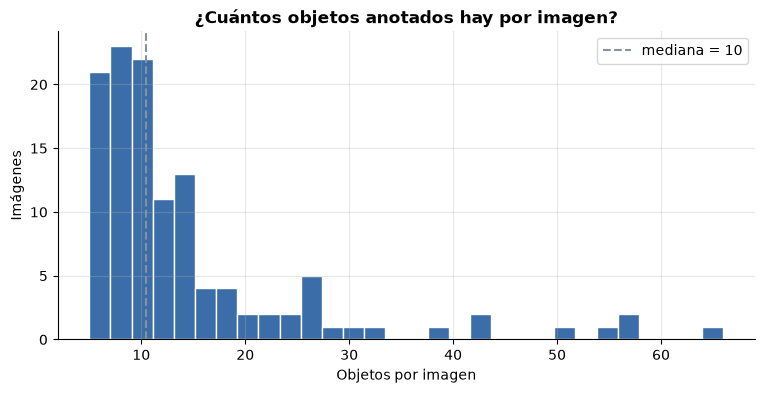

In [4]:
n_obj = objs.groupby("image_id").size().reindex(imgs.id, fill_value=0)
n_cls = objs.groupby("image_id").category_id.nunique().reindex(imgs.id, fill_value=0)
print(pd.DataFrame({"objetos": n_obj.describe(), "clases distintas": n_cls.describe()}).round(1))
print("Imagen más cargada:", n_obj.max(), "objetos | límite del schema: 300")

ax = n_obj.plot.hist(bins=30, color=AZUL, edgecolor="white")
ax.axvline(n_obj.median(), color=GRIS, ls="--", label=f"mediana = {n_obj.median():.0f}")
ax.set(title="¿Cuántos objetos anotados hay por imagen?", xlabel="Objetos por imagen", ylabel="Imágenes")
ax.legend(); plt.show()

### 1.3 ¿Qué tan chicos son los objetos?
Motiva: la elección del detector (YOLO-World rinde peor con objetos chicos) y la resolución de entrada.
Umbrales de referencia COCO: chico < 32² px, grande ≥ 96² px.

Chicos (<32² px): 54% | Medianos: 33% | Grandes (≥96² px): 13%
Percentiles de area_ratio: {0.1: 0.0002, 0.25: 0.0008, 0.5: 0.0029, 0.75: 0.0127, 0.9: 0.0468}


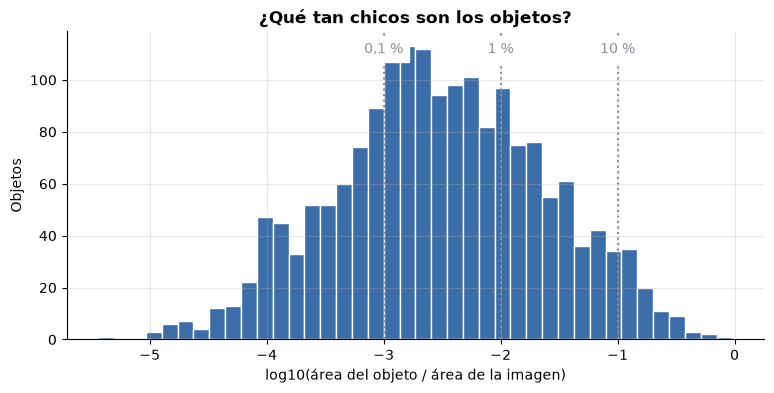

In [5]:
chico = (objs.area < 32**2).mean()
grande = (objs.area >= 96**2).mean()
print(f"Chicos (<32² px): {chico:.0%} | Medianos: {1 - chico - grande:.0%} | Grandes (≥96² px): {grande:.0%}")
print("Percentiles de area_ratio:", objs.area_ratio.quantile([.1, .25, .5, .75, .9]).round(4).to_dict())

ax = np.log10(objs.area_ratio).plot.hist(bins=40, color=AZUL, edgecolor="white")
for v, t in [(-3, "0,1 %"), (-2, "1 %"), (-1, "10 %")]:
    ax.axvline(v, color=GRIS, ls=":")
    ax.text(v, ax.get_ylim()[1] * 0.93, t, ha="center", color=GRIS, backgroundcolor="white")
ax.set(title="¿Qué tan chicos son los objetos?", xlabel="log10(área del objeto / área de la imagen)", ylabel="Objetos")
plt.show()

### 1.4 ¿Qué clases aparecen mucho y cuáles poco?
Motiva: cómo armar el vocabulario y qué clases van a pesar más en el F1.

Clases con al menos una anotación: 120 de 120
Clases con ≤ 3 instancias: 2
Clases presentes en una sola imagen: 0
Las 10 clases más frecuentes concentran el 20% de los objetos


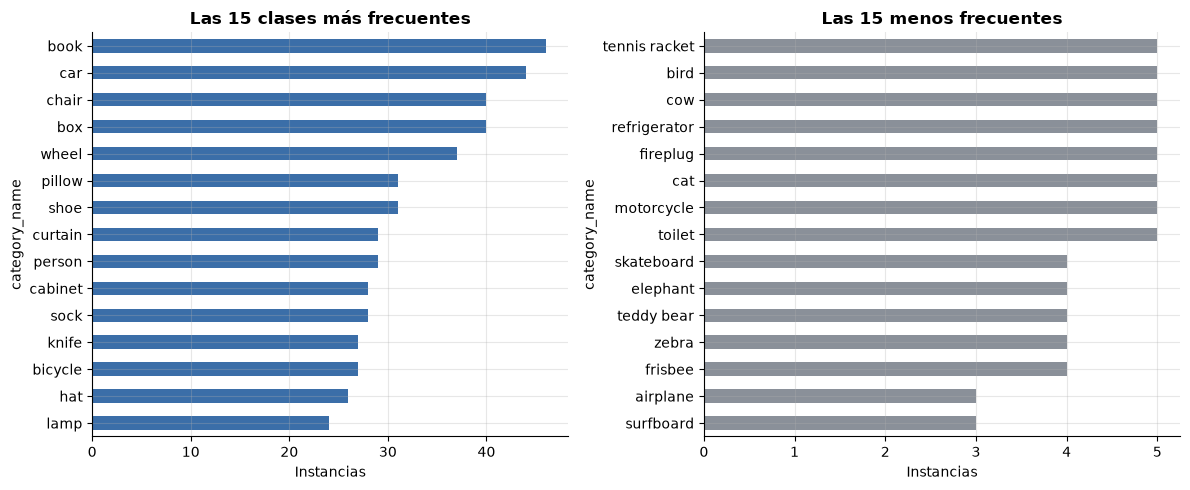

In [6]:
freq = objs.category_name.value_counts()
imgs_por_clase = objs.groupby("category_name").image_id.nunique()
print(f"Clases con al menos una anotación: {freq.size} de {len(cats)}")
print(f"Clases con ≤ 3 instancias: {(freq <= 3).sum()}")
print(f"Clases presentes en una sola imagen: {(imgs_por_clase == 1).sum()}")
print(f"Las 10 clases más frecuentes concentran el {freq.head(10).sum() / freq.sum():.0%} de los objetos")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
freq.head(15)[::-1].plot.barh(ax=axes[0], color=AZUL)
axes[0].set(title="Las 15 clases más frecuentes", xlabel="Instancias")
freq.tail(15)[::-1].plot.barh(ax=axes[1], color=GRIS)
axes[1].set(title="Las 15 menos frecuentes", xlabel="Instancias")
plt.tight_layout(); plt.show()

### 1.5 ¿Qué parte de las predicciones se puede evaluar? (LVIS)
Un par imagen-clase sólo se evalúa si es positivo (tiene anotaciones) o negativo verificado (`neg_category_ids`).
Motiva: la métrica local tiene que ignorar los pares no evaluables, y hay que reportar la cobertura.

In [7]:
pos = objs.groupby("image_id").category_id.apply(set).to_dict()
n_pos = sum(len(s) for s in pos.values())
n_neg = imgs.neg_category_ids.str.len().sum()
total = len(imgs) * len(cats)

print(f"Pares imagen-clase posibles: {total}")
print(f"  Positivos:             {n_pos:5d} ({n_pos / total:.1%})")
print(f"  Negativos verificados: {n_neg:5d} ({n_neg / total:.1%})")
print(f"  No evaluables:         {total - n_pos - n_neg:5d} ({1 - (n_pos + n_neg) / total:.1%})")

no_exh = sum(len(set(r.not_exhaustive_category_ids) & pos.get(r.id, set())) for r in imgs.itertuples())
print(f"Positivos marcados como no exhaustivos: {no_exh} ({no_exh / n_pos:.0%} de los positivos)")
solap = sum(len(set(r.neg_category_ids) & pos.get(r.id, set())) for r in imgs.itertuples())
print(f"Chequeo: clases a la vez positivas y negativas en una imagen: {solap} (debería ser 0)")

Pares imagen-clase posibles: 14400
  Positivos:               764 (5.3%)
  Negativos verificados:   118 (0.8%)
  No evaluables:         13518 (93.9%)
Positivos marcados como no exhaustivos: 47 (6% de los positivos)
Chequeo: clases a la vez positivas y negativas en una imagen: 0 (debería ser 0)


### 1.6 ¿Cuánto se solapan objetos de la misma clase?
Motiva: el umbral de NMS. Si objetos reales de la misma clase se solapan mucho, un NMS agresivo los borraría.

Pares de la misma clase dentro de una imagen: 3836
  con IoU > 0.3: 41 (1.1%)
  con IoU > 0.5: 19 (0.5%)
  con IoU > 0.7: 5 (0.1%)


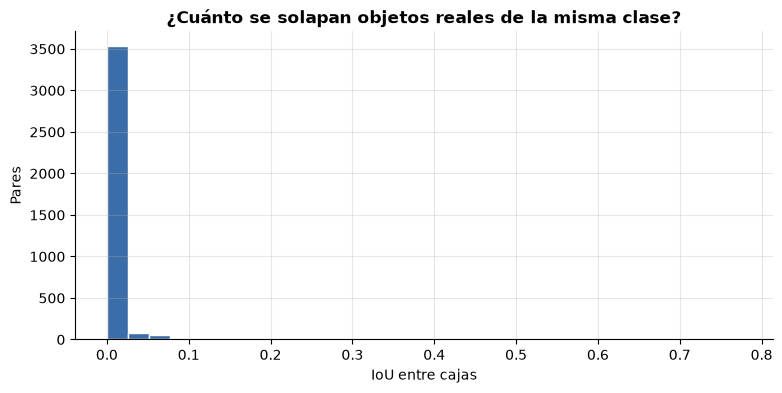

In [8]:
def iou_xywh(a, b):
    """IoU entre dos cajas en formato [x, y, ancho, alto]."""
    iw = max(0, min(a[0] + a[2], b[0] + b[2]) - max(a[0], b[0]))
    ih = max(0, min(a[1] + a[3], b[1] + b[3]) - max(a[1], b[1]))
    inter = iw * ih
    return inter / (a[2] * a[3] + b[2] * b[3] - inter + 1e-9)

ious = []
for _, g in objs.groupby(["image_id", "category_id"]):
    b = g.bbox.tolist()
    ious += [iou_xywh(b[i], b[j]) for i in range(len(b)) for j in range(i + 1, len(b))]
ious = np.array(ious)

print(f"Pares de la misma clase dentro de una imagen: {len(ious)}")
for t in (0.3, 0.5, 0.7):
    print(f"  con IoU > {t}: {(ious > t).sum()} ({(ious > t).mean():.1%})")

ax = pd.Series(ious).plot.hist(bins=30, color=AZUL, edgecolor="white")
ax.set(title="¿Cuánto se solapan objetos reales de la misma clase?", xlabel="IoU entre cajas", ylabel="Pares")
plt.show()

### 1.7 ¿Dónde caen los objetos en la grilla 3×3?
Motiva: valida la regla de posición del SceneJSON y muestra si hay sesgo espacial.

Proporción por zona:
col_0     0     1     2
row_0                  
0      0.07  0.08  0.09
1      0.12  0.19  0.13
2      0.09  0.14  0.09


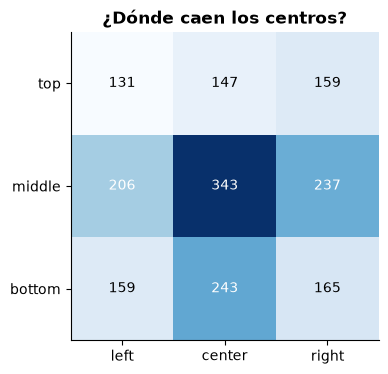

In [9]:
col = np.minimum((objs.cx / (objs.width / 3)).astype(int), 2)
fila = np.minimum((objs.cy / (objs.height / 3)).astype(int), 2)
grid = pd.crosstab(fila, col).reindex(index=range(3), columns=range(3), fill_value=0)
print("Proporción por zona:")
print((grid / grid.values.sum()).round(2))

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(grid, cmap="Blues"); ax.grid(False)
for r in range(3):
    for c in range(3):
        v = grid.iloc[r, c]
        ax.text(c, r, v, ha="center", va="center", color="white" if v > grid.values.max() / 2 else "black")
ax.set(xticks=range(3), yticks=range(3), xticklabels=["left", "center", "right"],
       yticklabels=["top", "middle", "bottom"], title="¿Dónde caen los centros?")
plt.show()

### 1.8 ¿Qué piden las preguntas y cuántas son ambiguas?
Para cada pregunta contamos cuántas instancias reales hay de la clase preguntada.
Motiva: qué operaciones implementar primero y cómo tratar "la instancia" cuando hay varias.

In [10]:
f2id = dict(zip(imgs.fname, imgs.id))
cnt = objs.groupby(["image_id", "category_name"]).size()

faltan = {c for l in qs.class_en for c in l} - set(cats.category_name)
print("Clases preguntadas que no están en el vocabulario:", faltan or "ninguna")
print("Imágenes de las preguntas que no aparecen en annotations:", set(qs.image_file) - set(f2id) or "ninguna")
print("Imágenes distintas en el benchmark:", qs.image_file.nunique())

qs["n_gt"] = qs.apply(lambda r: cnt.get((f2id[r.image_file], r.class_en[0]), 0) if r.class_en else np.nan, axis=1)
print("\nInstancias reales de la clase preguntada, por tipo:")
print(qs.groupby("type").n_gt.agg(["count", "mean", "min", "max"]).round(1))

amb = qs[qs.type.isin(["position", "size", "relation"]) & (qs.n_gt > 1)]
print(f"\nPreguntas sobre 'la instancia' con más de una instancia real: {len(amb)}")
print(amb[["question_id", "type", "class_en", "n_gt"]].to_string(index=False))
print("\nRespuestas de existencia que serían 'no' (0 instancias):", (qs[qs.type == "existence"].n_gt == 0).sum())

Clases preguntadas que no están en el vocabulario: ninguna
Imágenes de las preguntas que no aparecen en annotations: ninguna
Imágenes distintas en el benchmark: 20

Instancias reales de la clase preguntada, por tipo:
             count  mean  min  max
type                              
count           10   2.3  2.0  4.0
description      0   NaN  NaN  NaN
existence       10   0.8  0.0  4.0
position         5   1.0  1.0  1.0
relation        10   1.0  1.0  1.0
size             5   1.0  1.0  1.0

Preguntas sobre 'la instancia' con más de una instancia real: 0
Empty DataFrame
Columns: [question_id, type, class_en, n_gt]
Index: []

Respuestas de existencia que serían 'no' (0 instancias): 5


### 1.9 Verificación visual de las anotaciones
Dibujamos cajas (xywh) y polígonos para confirmar que el formato se interpreta bien. Mostramos la imagen con menos objetos, la mediana y la más cargada.

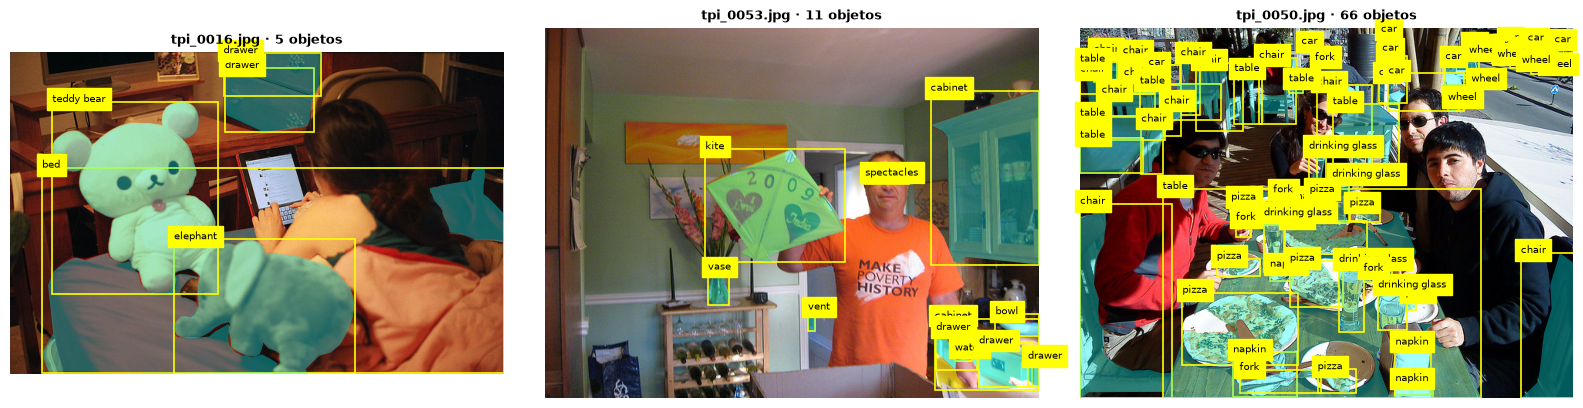

In [11]:
def mostrar(img_id, ax):
    info = imgs.set_index("id").loc[img_id]
    ax.imshow(Image.open(DEV / "images" / info.fname)); ax.axis("off")
    for a in (x for x in ann["annotations"] if x["image_id"] == img_id):
        x, y, w, h = a["bbox"]
        ax.add_patch(Rectangle((x, y), w, h, fill=False, ec="yellow", lw=1.2))
        for poly in a["segmentation"]:
            ax.add_patch(Polygon(np.array(poly).reshape(-1, 2), fc="cyan", alpha=0.35))
        ax.text(x, y, id2name[a["category_id"]], fontsize=7, backgroundcolor="yellow")
    ax.set_title(f"{info.fname} · {n_obj[img_id]} objetos", fontsize=9)

orden = n_obj.sort_values()
elegidas = [orden.index[0], orden.index[len(orden) // 2], orden.index[-1]]
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
for i, ax in zip(elegidas, axes):
    mostrar(i, ax)
plt.tight_layout(); plt.show()

### 1.10 Conclusiones del EDA: observación → decisión

| # | Observación | Decisión que motiva |
|---|---|---|
| 1.2 | 14,9 objetos por imagen en promedio (mediana 10,5; máx. 66) y entre 3 y 8 clases distintas por imagen. | El límite de 300 objetos del schema no es restricción. Dejamos un tope de detecciones holgado (~150) y no filtramos por cantidad. |
| 1.3 | El 54 % de los objetos es chico (< 32² px); la mediana ocupa el 0,29 % de la imagen. | Priorizamos detectores fuertes en objetos chicos (OWLv2 / Grounding DINO) sobre YOLO-World. La resolución de entrada es candidata a experimento controlado. |
| 1.4 | Las 120 clases tienen anotaciones; ninguna aparece en una sola imagen y las 10 más frecuentes suman sólo el 20 %. | Usamos el vocabulario completo de 120 clases: ninguna clase domina el F1, así que no conviene descartar clases raras. |
| 1.5 | El 93,9 % de los pares imagen-clase no es evaluable; sólo hay 118 negativos verificados (~1 por imagen) y el 6 % de los positivos es no exhaustivo. | Un falso positivo de una clase ausente casi nunca penaliza, pero los duplicados dentro de clases presentes sí. La métrica local implementa las reglas LVIS y reporta la cobertura. Esperamos un umbral óptimo bajo (a verificar con el barrido de F1). |
| 1.6 | Sólo el 0,5 % de los pares de objetos reales de la misma clase tiene IoU > 0,5. | NMS por clase con umbral 0,5 es seguro: casi no borra objetos reales. |
| 1.7 | Los centros se concentran en la fila del medio y la columna central (19 % en `center`), pero todas las zonas tienen al menos 7 %. | No hay sesgo fuerte: la regla de grilla 3×3 por centroide es adecuada. |
| 1.8 | Todas las clases preguntadas están en el vocabulario. En `position`, `size` y `relation` la clase tiene exactamente 1 instancia real; en `count` hay entre 2 y 4; 5 de 10 preguntas de `existence` tienen respuesta "no". | Si el detector predice varias instancias, se responde con la de mayor confianza. Para `existence` importa la precisión: un falso positivo cambia la respuesta. |
| 1.9 | Cajas y polígonos coinciden con los objetos de la foto. | Confirmado: `bbox` en formato `[x, y, ancho, alto]`. Para medir máscaras hay que rasterizar los polígonos (pycocotools). |

**Pendientes:** la definición oficial de `small / medium / large` y el orden del RLE (filas o columnas) se verifican en la Fase 3.

## 2. Detección de objetos

Objetivo de la fase: elegir y ajustar un detector open-vocabulary, medido con una métrica local que respeta las reglas de LVIS.

**Regla anti-fuga:** la función `detectar()` recibe sólo la imagen y el vocabulario (`categories.csv`). Las anotaciones se usan únicamente en `evaluar_cajas()`.

### 2.1 Métrica local (F1 de cajas con reglas LVIS)
Para cada imagen y clase:
- **Clase positiva** (tiene anotaciones): emparejamos predicciones con cajas reales de mayor a menor confianza, con IoU ≥ 0,5. Emparejada = TP; sin pareja = FP, salvo que la clase sea *no exhaustiva*, donde se ignora. Cajas reales sin pareja = FN.
- **Clase negativa verificada**: toda predicción es FP.
- **Resto**: la predicción se ignora (no es evaluable).

Supuesto: sumamos TP/FP/FN de todas las imágenes antes de calcular el F1 (micro). La métrica oficial de Kaggle puede agregar distinto.

In [12]:
from collections import defaultdict

img_meta = {r.id: r for r in imgs.itertuples()}
gt_by = defaultdict(list)
for a in ann["annotations"]:
    gt_by[(a["image_id"], a["category_id"])].append(a["bbox"])

def evaluar_cajas(preds, iou_thr=0.5, detalle=False):
    """preds: DataFrame con image_id, category_id, score y bbox [x, y, w, h]. Aplica las reglas LVIS."""
    grupos = {k: g.sort_values("score", ascending=False).bbox.tolist()
              for k, g in preds.groupby(["image_id", "category_id"])}
    cats_pred = defaultdict(set)
    for i, c in grupos:
        cats_pred[i].add(c)
    cnt = defaultdict(lambda: np.zeros(4, int))  # TP, FP, FN, ignoradas (por clase)
    for img_id, r in img_meta.items():
        neg, noexh = set(r.neg_category_ids), set(r.not_exhaustive_category_ids)
        for c in pos.get(img_id, set()) | cats_pred[img_id]:
            pb, gts = grupos.get((img_id, c), []), gt_by.get((img_id, c), [])
            if gts:
                usado = [False] * len(gts)
                for b in pb:
                    ious = [-1 if usado[k] else iou_xywh(b, g) for k, g in enumerate(gts)]
                    k = int(np.argmax(ious))
                    if ious[k] >= iou_thr:
                        usado[k] = True; cnt[c][0] += 1
                    elif c in noexh:
                        cnt[c][3] += 1
                    else:
                        cnt[c][1] += 1
                cnt[c][2] += usado.count(False)
            elif c in neg:
                cnt[c][1] += len(pb)
            else:
                cnt[c][3] += len(pb)
    tp, fp, fn, ign = np.sum(list(cnt.values()), axis=0)
    P = tp / (tp + fp) if tp + fp else 0.0
    R = tp / (tp + fn) if tp + fn else 0.0
    res = dict(P=P, R=R, F1=2 * P * R / (P + R) if P + R else 0.0, TP=tp, FP=fp, FN=fn, ignoradas=ign,
               cobertura=(tp + fp) / (tp + fp + ign) if tp + fp + ign else 0.0)
    if detalle:
        tabla = pd.DataFrame(cnt, index=["TP", "FP", "FN", "ign"]).T
        tabla.index = tabla.index.map(id2name)
        return res, tabla
    return res

# Pruebas de cordura de la métrica
gt_df = objs[["image_id", "category_id", "bbox"]].assign(score=1.0)
print("GT como predicción (esperado F1 = 1):", {k: round(float(v), 3) for k, v in evaluar_cajas(gt_df).items()})
corridas = gt_df.assign(bbox=gt_df.bbox.map(lambda b: [b[0] + b[2], b[1], b[2], b[3]]))
print("GT corrida un ancho (esperado F1 ≈ 0):", round(evaluar_cajas(corridas)["F1"], 3))
mitad = gt_df.sample(frac=0.5, random_state=0)
print("Sólo la mitad del GT (esperado P = 1, R ≈ 0,5):", {k: round(float(evaluar_cajas(mitad)[k]), 3) for k in ("P", "R")})

GT como predicción (esperado F1 = 1): {'P': 1.0, 'R': 1.0, 'F1': 1.0, 'TP': 1790.0, 'FP': 0.0, 'FN': 0.0, 'ignoradas': 0.0, 'cobertura': 1.0}
GT corrida un ancho (esperado F1 ≈ 0): 0.038
Sólo la mitad del GT (esperado P = 1, R ≈ 0,5): {'P': 1.0, 'R': 0.5}


### 2.2 Línea base: OWLv2 con el vocabulario completo
Elegimos **OWLv2** (`google/owlv2-base-patch16-ensemble`) como línea base: es open-vocabulary, procesa las 120 clases en una sola pasada y rinde bien con objetos chicos (54 % del dataset, ver 1.3).
Guardamos todas las detecciones con confianza ≥ 0,05 y después elegimos el umbral midiendo, sin volver a usar la GPU.

In [13]:
import time
import torch
from transformers import Owlv2Processor, Owlv2ForObjectDetection

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device, torch.cuda.get_device_name(0) if device == "cuda" else "")

MODELO = "google/owlv2-base-patch16-ensemble"
processor = Owlv2Processor.from_pretrained(MODELO)
model = Owlv2ForObjectDetection.from_pretrained(MODELO).to(device).eval()

# El nombre del post-procesado cambió entre versiones de transformers
post_proceso = getattr(processor, "post_process_grounded_object_detection", None) or processor.image_processor.post_process_object_detection

VOCAB = cats.category_name.tolist()
CAT_IDS = cats.category_id.tolist()
PROMPTS = [f"a photo of a {n}" for n in VOCAB]

@torch.no_grad()
def detectar(img_path, umbral=0.05):
    """Recibe SÓLO una imagen y el vocabulario. No lee anotaciones."""
    im = Image.open(img_path).convert("RGB")
    W, H = im.size
    inp = processor(text=[PROMPTS], images=im, return_tensors="pt").to(device)
    out = model(**inp)
    S = max(W, H)  # OWLv2 rellena la imagen hasta hacerla cuadrada
    res = post_proceso(out, threshold=umbral, target_sizes=torch.tensor([[S, S]], device=device))[0]
    filas = []
    for (x1, y1, x2, y2), s, l in zip(res["boxes"].tolist(), res["scores"].tolist(), res["labels"].tolist()):
        x1, y1, x2, y2 = max(0, x1), max(0, y1), min(W, x2), min(H, y2)
        if x2 > x1 and y2 > y1:
            filas.append(dict(category_id=CAT_IDS[l], score=s, bbox=[x1, y1, x2 - x1, y2 - y1]))
    return filas

# Prueba con una imagen
t0 = time.time()
prueba = pd.DataFrame(detectar(DEV / "images" / imgs.fname.iloc[0]))
print(f"{len(prueba)} detecciones en {time.time() - t0:.1f} s")
print(prueba.assign(clase=prueba.category_id.map(id2name)).sort_values("score", ascending=False).head(10))

Dispositivo: cpu 


Loading weights: 100%|██████████| 418/418 [00:01<00:00, 324.82it/s]


89 detecciones en 10.1 s
    category_id     score                                             bbox  \
84           19  0.588521    [66.894531, 476.571106, 60.007111, 114.57196]   
4            86  0.492610   [144.478485, 38.41116, 201.260925, 192.955814]   
20           67  0.456929   [126.543289, 193.549286, 22.998474, 17.104645]   
45           89  0.440910    [109.091148, 315.7229, 268.838905, 45.384705]   
56           11  0.380728    [158.063339, 392.080688, 70.592651, 7.692413]   
57           11  0.359881    [257.736237, 390.858612, 68.900848, 7.989716]   
1           114  0.355025     [146.575867, 35.228539, 197.3573, 39.307808]   
60           62  0.346228  [246.345963, 376.513214, 125.851334, 31.338104]   
53           62  0.338854   [119.655594, 379.22876, 124.638855, 31.239838]   
19          114  0.314424   [179.969543, 167.803665, 51.855042, 58.014526]   

          clase  
84    trash can  
4        mirror  
20  wall socket  
45         sink  
56       handle  
57      

### 2.3 Detección sobre las 120 imágenes de desarrollo
Corremos OWLv2 una sola vez y guardamos las detecciones crudas en `/kaggle/working/`. Todas las decisiones que siguen (NMS, umbral) se ajustan sobre este archivo, sin gastar más GPU.

In [14]:
SALIDA = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("salidas_local")
SALIDA.mkdir(exist_ok=True)
filas, tiempos = [], []
for img_id, fname in imgs[["id", "fname"]].itertuples(index=False):
    t0 = time.time()
    for d in detectar(DEV / "images" / fname, umbral=0.05):
        d["image_id"] = img_id
        filas.append(d)
    tiempos.append(time.time() - t0)

dets = pd.DataFrame(filas)
dets.to_pickle(SALIDA / "dets_owlv2_base_dev.pkl")
print(f"{len(dets)} detecciones crudas | {np.mean(tiempos):.2f} s por imagen | total {np.sum(tiempos) / 60:.1f} min")
print("Detecciones por imagen (umbral 0,05):", dets.groupby("image_id").size().describe().round(1).to_dict())

20404 detecciones crudas | 8.78 s por imagen | total 17.6 min
Detecciones por imagen (umbral 0,05): {'count': 120.0, 'mean': 170.0, 'std': 122.6, 'min': 38.0, '25%': 80.8, '50%': 129.5, '75%': 221.8, 'max': 727.0}


### 2.4 NMS por clase y elección del umbral de confianza
Aplicamos NMS por clase con IoU 0,5 (justificado en 1.6) y barremos el umbral de confianza. Elegimos el umbral que maximiza el F1 en desarrollo; también mostramos cuántas predicciones fueron evaluables (cobertura, ver 1.5).

NMS: 20404 -> 16576 detecciones
 umbral     P     R    F1   TP   FP   FN  ignoradas  cobertura
  0.050 0.300 0.765 0.431 1370 3199  420      12007      0.276
  0.075 0.399 0.747 0.520 1337 2011  453       7544      0.307
  0.100 0.489 0.721 0.583 1291 1347  499       5241      0.335
  0.125 0.558 0.696 0.619 1245  987  545       3791      0.371
  0.150 0.626 0.661 0.643 1184  707  606       2812      0.402
  0.200 0.733 0.579 0.647 1036  378  754       1637      0.463
  0.250 0.817 0.505 0.624  904  202  886        949      0.538
  0.300 0.865 0.431 0.575  772  121 1018        564      0.613
  0.400 0.923 0.276 0.425  494   41 1296        179      0.749
  0.500 0.958 0.139 0.242  248   11 1542         44      0.855

Mejor umbral: 0.2 -> F1 = 0.647 (P = 0.733, R = 0.579)
Sin NMS, mismo umbral: 0.634


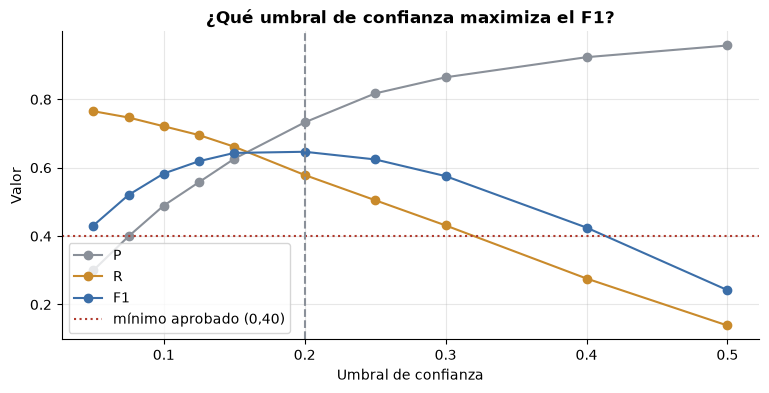

In [16]:
from torchvision.ops import batched_nms

def aplicar_nms(df, iou=0.5):
    """NMS por clase dentro de cada imagen. Las cajas vienen en [x, y, w, h]."""
    partes = []
    for _, g in df.groupby("image_id"):
        b = torch.tensor(g.bbox.tolist(), dtype=torch.float32)
        b[:, 2:] += b[:, :2]  # a [x1, y1, x2, y2]
        keep = batched_nms(b, torch.tensor(g.score.values, dtype=torch.float32), torch.tensor(g.category_id.values), iou)
        partes.append(g.iloc[keep.numpy()])
    return pd.concat(partes, ignore_index=True)

dets_nms = aplicar_nms(dets)
print(f"NMS: {len(dets)} -> {len(dets_nms)} detecciones")

umbrales = [0.05, 0.075, 0.1, 0.125, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5]
curva = pd.DataFrame([dict(umbral=u, **evaluar_cajas(dets_nms[dets_nms.score >= u])) for u in umbrales])
print(curva.round(3).to_string(index=False))
mejor = curva.loc[curva.F1.idxmax()]
UMBRAL = float(mejor.umbral)
print(f"\nMejor umbral: {UMBRAL} -> F1 = {mejor.F1:.3f} (P = {mejor.P:.3f}, R = {mejor.R:.3f})")
print("Sin NMS, mismo umbral:", round(evaluar_cajas(dets[dets.score >= UMBRAL])["F1"], 3))

ax = curva.plot(x="umbral", y=["P", "R", "F1"], marker="o", color=[GRIS, "#c98a2b", AZUL])
ax.axhline(0.40, color="#b03a2e", ls=":", label="mínimo aprobado (0,40)")
ax.axvline(UMBRAL, color=GRIS, ls="--")
ax.set(title="¿Qué umbral de confianza maximiza el F1?", xlabel="Umbral de confianza", ylabel="Valor")
ax.legend(); plt.show()

### 2.5 Análisis de errores: ¿dónde pierde puntos el detector?
Con el umbral elegido miramos qué objetos reales no se detectan (FN) según su tamaño y su clase, y qué clases generan más falsos positivos. Esto define el experimento controlado.

Recall por tamaño del objeto:
               objetos  recall
tamaño                        
chico (<32²)       742   0.435
mediano            673   0.657
grande (≥96²)      375   0.723

Las 10 clases con peor recall (con al menos 5 objetos reales):
             TP  FN  recall
person        1  28    0.03
book          6  40    0.13
strap         3  20    0.13
doorknob      2   8    0.20
curtain       6  23    0.21
shoe          7  24    0.23
car          13  31    0.30
signboard     5  11    0.31
pole          7  15    0.32
streetlight   3   6    0.33

Las 10 clases con más falsos positivos:
               TP  FP  FN
ski            14  18  10
streetlight     3  14   6
knife          17  12  10
flag           12  12   2
traffic light  13  11   3
baseball bat    7  10   4
pizza          11  10   2
cabinet        10   9  18
knob           16   9   8
wall socket    11   8   2


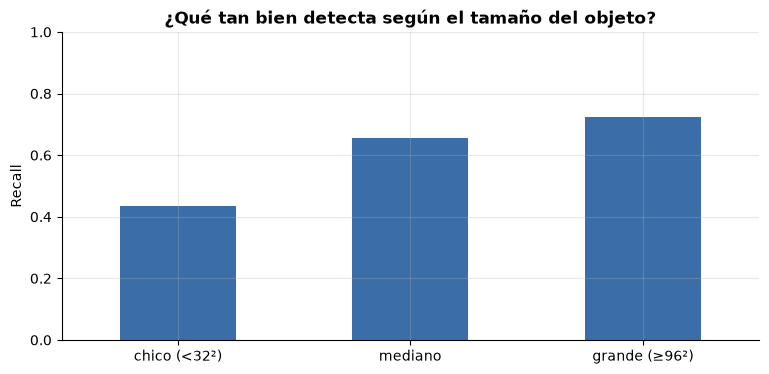

In [17]:
def gt_detectados(preds, iou_thr=0.5):
    """Marca cada objeto real como detectado o no (mismo emparejamiento que evaluar_cajas)."""
    grupos = {k: g.sort_values("score", ascending=False).bbox.tolist()
              for k, g in preds.groupby(["image_id", "category_id"])}
    filas = []
    for (img_id, c), gts in gt_by.items():
        usado = [False] * len(gts)
        for b in grupos.get((img_id, c), []):
            ious = [-1 if usado[k] else iou_xywh(b, g) for k, g in enumerate(gts)]
            k = int(np.argmax(ious))
            if ious[k] >= iou_thr:
                usado[k] = True
        filas += [(img_id, c, g[2] * g[3], u) for g, u in zip(gts, usado)]
    return pd.DataFrame(filas, columns=["image_id", "category_id", "area", "detectado"])

sel = dets_nms[dets_nms.score >= UMBRAL]
gd = gt_detectados(sel)
gd["tamaño"] = pd.cut(gd.area, [0, 32**2, 96**2, np.inf], labels=["chico (<32²)", "mediano", "grande (≥96²)"])
print("Recall por tamaño del objeto:")
print(gd.groupby("tamaño", observed=True).detectado.agg(["count", "mean"]).rename(columns={"count": "objetos", "mean": "recall"}).round(3))

res, tabla = evaluar_cajas(sel, detalle=True)
tabla["recall"] = tabla.TP / (tabla.TP + tabla.FN).replace(0, np.nan)
print("\nLas 10 clases con peor recall (con al menos 5 objetos reales):")
print(tabla[(tabla.TP + tabla.FN) >= 5].sort_values("recall").head(10)[["TP", "FN", "recall"]].round(2))
print("\nLas 10 clases con más falsos positivos:")
print(tabla.sort_values("FP", ascending=False).head(10)[["TP", "FP", "FN"]])

ax = gd.groupby("tamaño", observed=True).detectado.mean().plot.bar(color=AZUL, rot=0)
ax.set(title="¿Qué tan bien detecta según el tamaño del objeto?", xlabel="", ylabel="Recall", ylim=(0, 1))
plt.show()

### 2.6 Diagnóstico: ¿por qué casi no detecta personas?
`person` tiene recall 0,03, algo raro para OWLv2. Hipótesis: el post-procesado estándar asigna **una sola clase por caja** (la de mayor puntaje). Una persona puede competir con clases que la cubren, como prendas de ropa, y perder. Para cada persona real buscamos la caja predicha que mejor la cubre y miramos qué clase recibió.

In [18]:
def clase_asignada(nombre):
    """Para cada objeto real de la clase, qué clase tiene la caja cruda (umbral 0,05) que mejor lo cubre."""
    cid = cats.set_index("category_name").category_id[nombre]
    res = []
    for (img_id, c), gts in gt_by.items():
        if c != cid:
            continue
        d_img = dets[dets.image_id == img_id]
        for g in gts:
            ious = d_img.bbox.map(lambda b: iou_xywh(b, g))
            m = d_img[ious >= 0.5]
            res.append(id2name[m.loc[m.score.idxmax(), "category_id"]] if len(m) else "(ninguna caja)")
    return pd.Series(res).value_counts()

for nombre in ["person", "book", "shoe"]:
    print(f"--- {nombre}: clase que recibe la mejor caja ---")
    print(clase_asignada(nombre).head(6).to_string(), "\n")

--- person: clase que recibe la mejor caja ---
person     17
shirt       5
jacket      3
book        1
bed         1
bicycle     1 

--- book: clase que recibe la mejor caja ---
(ninguna caja)    26
book              17
cell phone         1
handle             1
box                1 

--- shoe: clase que recibe la mejor caja ---
shoe              27
(ninguna caja)     3
boot               1 



**Resultado del diagnóstico:** de 29 personas, 17 tienen una caja etiquetada `person` pero con confianza baja (no superan el umbral 0,2), y 8 perdieron la etiqueta contra `shirt` o `jacket`. En `book`, 26 de 43 no tienen ninguna caja: es el problema de los objetos chicos (1.3).

### 2.7 Experimento controlado: una etiqueta por caja vs. varias
**Variable que cambiamos:** cuántas clases puede recibir cada caja predicha (k = 1, 2 o 3, las de mayor puntaje). **Fijo:** modelo, prompts, resolución, NMS 0,5 y la métrica.
Hipótesis: con k > 1 recuperamos objetos que pierden contra clases que se solapan (persona vs. ropa), a costa de algunos falsos positivos.
Control: con k = 1 tenemos que reproducir la línea base (F1 = 0,646).

33298 detecciones crudas en 16.8 min

Mejor F1 de cada variante:
 k  umbral     P     R    F1   TP  FP  FN  cobertura
 1     0.2 0.733 0.579 0.647 1036 378 754      0.463
 2     0.2 0.724 0.606 0.660 1085 413 705      0.431
 3     0.2 0.724 0.609 0.662 1090 415 700      0.429


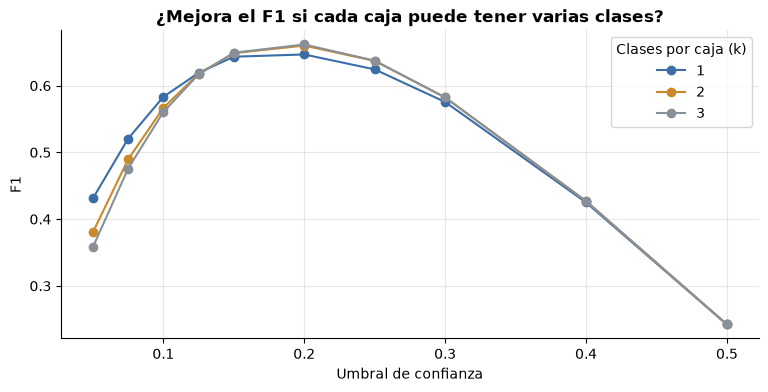

In [19]:
@torch.no_grad()
def detectar_multi(img_path, umbral=0.05, k_max=3):
    """Como detectar(), pero cada caja puede recibir hasta k_max clases. Recibe SÓLO la imagen y el vocabulario."""
    im = Image.open(img_path).convert("RGB")
    W, H = im.size
    inp = processor(text=[PROMPTS], images=im, return_tensors="pt").to(device)
    out = model(**inp)
    probs = out.logits[0].sigmoid()           # (cajas, clases)
    top_p, top_c = probs.topk(k_max, dim=1)   # las k clases con mayor puntaje por caja
    cajas = out.pred_boxes[0].tolist()        # (cx, cy, w, h) normalizadas al cuadrado rellenado
    S = max(W, H)
    filas = []
    for i, rango in (top_p >= umbral).nonzero().tolist():
        cx, cy, w, h = [v * S for v in cajas[i]]
        x1, y1, x2, y2 = max(0, cx - w / 2), max(0, cy - h / 2), min(W, cx + w / 2), min(H, cy + h / 2)
        if x2 > x1 and y2 > y1:
            filas.append(dict(category_id=CAT_IDS[top_c[i, rango].item()], score=top_p[i, rango].item(),
                              bbox=[x1, y1, x2 - x1, y2 - y1], rango=rango))
    return filas

filas = []
t0 = time.time()
for img_id, fname in imgs[["id", "fname"]].itertuples(index=False):
    for d in detectar_multi(DEV / "images" / fname):
        d["image_id"] = img_id
        filas.append(d)
dets_multi = pd.DataFrame(filas)
dets_multi.to_pickle(SALIDA / "dets_owlv2_base_dev_top3.pkl")
print(f"{len(dets_multi)} detecciones crudas en {(time.time() - t0) / 60:.1f} min")

resultados = []
for k in (1, 2, 3):
    dk = aplicar_nms(dets_multi[dets_multi.rango < k])
    for u in umbrales:
        resultados.append(dict(k=k, umbral=u, **evaluar_cajas(dk[dk.score >= u])))
exp = pd.DataFrame(resultados)
resumen = exp.loc[exp.groupby("k").F1.idxmax(), ["k", "umbral", "P", "R", "F1", "TP", "FP", "FN", "cobertura"]]
print("\nMejor F1 de cada variante:")
print(resumen.round(3).to_string(index=False))

ax = exp.pivot(index="umbral", columns="k", values="F1").plot(marker="o", color=[AZUL, "#c98a2b", GRIS])
ax.set(title="¿Mejora el F1 si cada caja puede tener varias clases?", xlabel="Umbral de confianza", ylabel="F1")
ax.legend(title="Clases por caja (k)"); plt.show()

### 2.8 Conclusiones de la Fase 2

| Configuración | Umbral | P | R | F1 | TP | FP | FN |
|---|---|---|---|---|---|---|---|
| OWLv2 base, sin NMS | 0,20 | | | 0,633 | | | |
| Línea base: OWLv2 base + NMS 0,5, 1 clase por caja | 0,20 | 0,732 | 0,578 | 0,646 | 1035 | 378 | 755 |
| **Elegida: 2 clases por caja** | 0,20 | 0,724 | 0,606 | **0,660** | 1084 | 413 | 706 |
| 3 clases por caja | 0,20 | 0,724 | 0,608 | 0,661 | 1089 | 415 | 701 |

**Lectura del experimento.** Permitir varias clases por caja recupera 49 objetos reales a cambio de 35 falsos positivos más, y sube el F1 en 1,4 puntos. Elegimos **k = 2**: k = 3 casi no agrega (+0,001) y genera más detecciones. El control con k = 1 reprodujo exactamente la línea base, así que la mejora se debe sólo a la variable cambiada. El umbral óptimo se mantuvo en 0,20 en las tres variantes.

**Qué sigue limitando el resultado:**
- **Recall bajo en objetos chicos:** 0,43 en chicos contra 0,72 en grandes. En `book`, 26 de 43 objetos no tienen ninguna caja. Candidato a experimento: OWLv2 *large* o mayor resolución de entrada.
- **Confianzas no calibradas entre clases:** `person` y `shoe` se detectan pero con puntaje bajo, y un umbral único los deja afuera. Un umbral por clase ajustado con sólo 120 imágenes tendría riesgo alto de sobreajuste, así que lo dejamos como limitación documentada.
- **Falsos positivos concentrados** en clases parecidas entre sí (`ski`, `streetlight`, `knife`, `traffic light`).

**Configuración que pasa a la Fase 3:** OWLv2 base, prompt `"a photo of a {clase}"`, hasta 2 clases por caja, NMS por clase 0,5 y umbral 0,20.

*Nota:* estas métricas son locales (F1 micro con reglas LVIS). El valor oficial se confirma con el primer envío a Kaggle.

## 3. Segmentación (SAM2) y propiedades derivadas

El detector dice **qué es y dónde está, aproximadamente** (caja). SAM2 dice **exactamente qué píxeles** ocupa, pero no sabe qué es: necesita que le pasemos la caja como prompt. Por eso va segundo en la pipeline.

De la máscara salen las propiedades **derivadas** del SceneJSON: `centroid`, `area_ratio`, `position` (grilla 3×3) y `size`; y entre pares de objetos, las `relations`.

### 3.1 Carga de SAM2 y prueba con una imagen

c:\Users\matus\Desktop\work\IA\TPs\TP primavera\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\matus\.cache\huggingface\hub\models--facebook--sam2.1-hiera-small. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
[transformers] `Sam2ImageProcessorFast` is deprecated. The `Fast` suffix for image proc

SAM2 no disponible, uso SAM v1: ImportError('\nSam2ImageProcessor requires the Torchvision library but it was not found in your environment. Check out the instructions on the\ninstallation page: https://pytorch.org/get-started/local


c:\Users\matus\Desktop\work\IA\TPs\TP primavera\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\matus\.cache\huggingface\hub\models--facebook--sam-vit-base. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\matus\Desktop\work\IA\TPs\TP primavera\.venv\Lib\site-packages\huggingface_hub\file_

Segmentador: facebook/sam-vit-base
Detecciones finales en desarrollo: 3479 (umbral 0.2)
51 máscaras en 10.93 s | forma (480, 640) | imagen 480x640


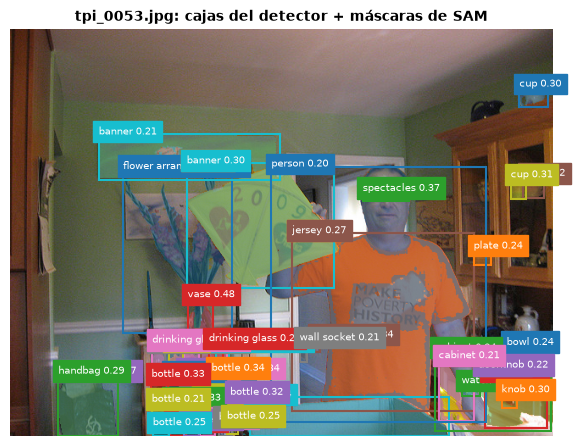

In [20]:
try:
    from transformers import Sam2Processor, Sam2Model
    SAM_ID = "facebook/sam2.1-hiera-small"
    sam_proc = Sam2Processor.from_pretrained(SAM_ID)
    sam = Sam2Model.from_pretrained(SAM_ID).to(device).eval()
    ES_SAM2 = True
except Exception as e:  # respaldo si esta versión de transformers no trae SAM2
    print("SAM2 no disponible, uso SAM v1:", repr(e)[:200])
    from transformers import SamProcessor, SamModel
    SAM_ID = "facebook/sam-vit-base"
    sam_proc = SamProcessor.from_pretrained(SAM_ID)
    sam = SamModel.from_pretrained(SAM_ID).to(device).eval()
    ES_SAM2 = False
print("Segmentador:", SAM_ID)

@torch.no_grad()
def segmentar(im, cajas_xywh, lote=64):
    """Recibe la imagen y las cajas del detector. Devuelve una máscara booleana (H, W) por caja."""
    mascaras = []
    for i in range(0, len(cajas_xywh), lote):
        xyxy = [[x, y, x + w, y + h] for x, y, w, h in cajas_xywh[i:i + lote]]
        inp = sam_proc(images=im, input_boxes=[xyxy], return_tensors="pt").to(device)
        out = sam(**inp, multimask_output=False)
        if ES_SAM2:
            m = sam_proc.post_process_masks(out.pred_masks.cpu(), inp["original_sizes"].cpu())[0]
        else:
            m = sam_proc.post_process_masks(out.pred_masks.cpu(), inp["original_sizes"].cpu(), inp["reshaped_input_sizes"].cpu())[0]
        mascaras += [mm[0].numpy().astype(bool) for mm in m]
    return mascaras

# Detecciones finales de la Fase 2: hasta 2 clases por caja, NMS 0,5, umbral 0,20
dk = aplicar_nms(dets_multi[dets_multi.rango < 2])
dets_final = dk[dk.score >= UMBRAL].reset_index(drop=True)
print(f"Detecciones finales en desarrollo: {len(dets_final)} (umbral {UMBRAL})")

# Prueba con la imagen de la verificación visual 1.9 (11 objetos)
img_id = elegidas[1]
info = img_meta[img_id]
im = Image.open(DEV / "images" / info.fname).convert("RGB")
d_img = dets_final[dets_final.image_id == img_id]
t0 = time.time()
masks = segmentar(im, d_img.bbox.tolist())
print(f"{len(masks)} máscaras en {time.time() - t0:.2f} s | forma {masks[0].shape} | imagen {info.height}x{info.width}")

fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(im); ax.axis("off")
colores = plt.cm.tab10(np.arange(len(masks)) % 10)
for m, (_, d), col in zip(masks, d_img.iterrows(), colores):
    capa = np.zeros((*m.shape, 4)); capa[m] = [*col[:3], 0.45]
    ax.imshow(capa)
    x, y, w, h = d.bbox
    ax.add_patch(Rectangle((x, y), w, h, fill=False, ec=col, lw=1.5))
    ax.text(x, y, f"{id2name[d.category_id]} {d.score:.2f}", fontsize=7, color="white", backgroundcolor=col)
ax.set_title(f"{info.fname}: cajas del detector + máscaras de SAM", fontsize=10)
plt.show()

### 3.2 Codificación RLE y test de ida y vuelta
El schema pide la máscara como RLE **no comprimido**: `{"size": [alto, ancho], "counts": [...]}`, donde `counts` son largos de corridas alternadas que **arrancan contando ceros**. El `size` en orden `[alto, ancho]` es la convención de COCO (lo confirma `sample_submission.csv`), así que usamos también su orden de aplanado: **por columnas** (Fortran).

Un error acá deja el F1 de máscaras casi en 0 aunque las máscaras sean perfectas, por eso lo testeamos tres veces: contra el ejemplo oficial, con máscaras al azar y contra `pycocotools`.

In [21]:
from pycocotools import mask as mask_utils

def rle_encode(mask):
    """Máscara booleana (H, W) -> RLE no comprimido estilo COCO (por columnas, arranca contando ceros)."""
    v = mask.ravel(order="F").astype(np.uint8)
    cambios = np.flatnonzero(np.diff(v)) + 1
    counts = np.diff(np.concatenate([[0], cambios, [v.size]])).tolist()
    if v[0] == 1:
        counts = [0] + counts
    return {"size": [int(mask.shape[0]), int(mask.shape[1])], "counts": counts}

def rle_decode(rle):
    h, w = rle["size"]
    v = np.zeros(h * w, dtype=bool)
    pos, valor = 0, False
    for c in rle["counts"]:
        if valor:
            v[pos:pos + c] = True
        pos += c
        valor = not valor
    return v.reshape((h, w), order="F")

# Test 1: el ejemplo oficial de sample_submission (un solo píxel en la esquina)
ej = json.loads(sub.iloc[0].SceneJSON)["objects"][0]["mask"]
m_ej = rle_decode(ej)
print("Test 1 | píxeles en 1:", m_ej.sum(), "| en (0,0):", m_ej[0, 0], "| re-codifica igual:", rle_encode(m_ej) == ej)

# Test 2: ida y vuelta con 200 máscaras al azar, incluso las que arrancan en 1 o están vacías
rng = np.random.default_rng(0)
ok = all(np.array_equal(rle_decode(rle_encode(m)), m)
         for m in [rng.random((rng.integers(1, 60), rng.integers(1, 60))) < rng.random() for _ in range(200)])
print("Test 2 | ida y vuelta en 200 máscaras al azar:", ok)

# Test 3: pycocotools tiene que leer nuestro RLE y obtener la misma máscara (mismo orden de píxeles)
ok3 = True
for m in masks[:10]:
    r = rle_encode(m)
    dec = mask_utils.decode(mask_utils.frPyObjects(r, *r["size"]))
    ok3 &= np.array_equal(dec.astype(bool), m)
print("Test 3 | pycocotools decodifica igual (10 máscaras de SAM):", ok3)
largo = np.mean([len(rle_encode(m)["counts"]) for m in masks])
print(f"Largo medio de counts: {largo:.0f} números por máscara (contra {masks[0].size} píxeles)")

Test 1 | píxeles en 1: 1 | en (0,0): True | re-codifica igual: True
Test 2 | ida y vuelta en 200 máscaras al azar: True
Test 3 | pycocotools decodifica igual (10 máscaras de SAM): True
Largo medio de counts: 146 números por máscara (contra 307200 píxeles)


### 3.3 Segmentación de las 120 imágenes y F1 de máscaras
Segmentamos todas las detecciones finales de la Fase 2 y medimos el F1 de máscaras con las mismas reglas LVIS, pero con IoU entre máscaras.

**Experimento controlado:** comparamos SAM2 contra una línea base trivial que usa **la caja rellena como máscara**. Mismo detector, mismas detecciones, misma métrica: sólo cambia de dónde sale la máscara. Si SAM2 no le gana a la caja, no está aportando nada.

In [22]:
# Máscaras reales: polígonos de annotations.json -> RLE de pycocotools (sólo para evaluar)
gt_rle = defaultdict(list)
for a in ann["annotations"]:
    r = img_meta[a["image_id"]]
    gt_rle[(a["image_id"], a["category_id"])].append(
        mask_utils.merge(mask_utils.frPyObjects(a["segmentation"], r.height, r.width)))

def a_rle_coco(rle):
    """Acepta nuestro RLE no comprimido o uno ya comprimido por pycocotools."""
    return mask_utils.frPyObjects(rle, *rle["size"]) if isinstance(rle["counts"], list) else rle

def evaluar_mascaras(preds, col="rle", iou_thr=0.5):
    """Mismas reglas LVIS que evaluar_cajas, pero con IoU entre máscaras."""
    grupos = {k: g.sort_values("score", ascending=False)[col].tolist()
              for k, g in preds.groupby(["image_id", "category_id"])}
    cats_pred = defaultdict(set)
    for i, c in grupos:
        cats_pred[i].add(c)
    tp = fp = fn = ign = 0
    for img_id, r in img_meta.items():
        neg, noexh = set(r.neg_category_ids), set(r.not_exhaustive_category_ids)
        for c in pos.get(img_id, set()) | cats_pred[img_id]:
            pm, gts = grupos.get((img_id, c), []), gt_rle.get((img_id, c), [])
            if gts:
                usado = np.zeros(len(gts), bool)
                if pm:
                    M = np.atleast_2d(mask_utils.iou([a_rle_coco(m) for m in pm], gts, [0] * len(gts)))
                    for i in range(len(pm)):
                        fila = np.where(usado, -1, M[i])
                        k = int(np.argmax(fila))
                        if fila[k] >= iou_thr:
                            usado[k] = True; tp += 1
                        elif c in noexh:
                            ign += 1
                        else:
                            fp += 1
                fn += int((~usado).sum())
            elif c in neg:
                fp += len(pm)
            else:
                ign += len(pm)
    P = tp / (tp + fp) if tp + fp else 0.0
    R = tp / (tp + fn) if tp + fn else 0.0
    return dict(P=P, R=R, F1=2 * P * R / (P + R) if P + R else 0.0, TP=tp, FP=fp, FN=fn, ignoradas=ign)

gt_pred = pd.DataFrame([dict(image_id=i, category_id=c, score=1.0, rle=m) for (i, c), ms in gt_rle.items() for m in ms])
print("Cordura | máscaras reales como predicción (esperado F1 = 1):", round(evaluar_mascaras(gt_pred)["F1"], 3))

def caja_a_mascara(b, H, W):
    m = np.zeros((H, W), bool)
    x, y, w, h = b
    m[int(round(y)):int(round(y + h)), int(round(x)):int(round(x + w))] = True
    return m

rle_sam, rle_caja, vacias = {}, {}, 0
t0 = time.time()
for img_id, d_img in dets_final.groupby("image_id", sort=False):
    r = img_meta[img_id]
    im = Image.open(DEV / "images" / r.fname).convert("RGB")
    for idx, b, m in zip(d_img.index, d_img.bbox, segmentar(im, d_img.bbox.tolist())):
        mc = caja_a_mascara(b, r.height, r.width)
        if m.sum() == 0:  # SAM no devolvió píxeles: usamos la caja como respaldo
            m, vacias = mc, vacias + 1
        rle_sam[idx], rle_caja[idx] = rle_encode(m), rle_encode(mc)
dets_final["rle_sam"] = pd.Series(rle_sam)
dets_final["rle_caja"] = pd.Series(rle_caja)
print(f"{len(dets_final)} máscaras en {(time.time() - t0) / 60:.1f} min | máscaras vacías reemplazadas por la caja: {vacias}")
dets_final.to_pickle(SALIDA / "dets_final_dev_con_mascaras.pkl")

comp = pd.DataFrame([dict(fuente="Caja como máscara (línea base)", **evaluar_mascaras(dets_final, "rle_caja")),
                     dict(fuente="SAM2 con la caja como prompt", **evaluar_mascaras(dets_final, "rle_sam"))])
print("\nF1 de máscaras (IoU de máscara ≥ 0,5):")
print(comp.round(3).to_string(index=False))
print("\nReferencia, F1 de cajas de las mismas detecciones:", round(evaluar_cajas(dets_final)["F1"], 3))

Cordura | máscaras reales como predicción (esperado F1 = 1): 1.0
3479 máscaras en 16.7 min | máscaras vacías reemplazadas por la caja: 2

F1 de máscaras (IoU de máscara ≥ 0,5):
                        fuente     P     R    F1   TP  FP   FN  ignoradas
Caja como máscara (línea base) 0.469 0.383 0.422  685 775 1105       2019
  SAM2 con la caja como prompt 0.680 0.565 0.617 1011 475  779       1993

Referencia, F1 de cajas de las mismas detecciones: 0.66


### 3.4 Propiedades derivadas y relaciones espaciales
Estas propiedades **no las predice ningún modelo**: se calculan con código a partir de la máscara. Son *derivadas* y por eso son auditables.

| Campo | Regla |
|---|---|
| `centroid` | promedio de las coordenadas (x, y) de los píxeles de la máscara |
| `area_ratio` | píxeles de la máscara / píxeles de la imagen |
| `position` | celda de la grilla 3×3 donde cae el centroide |
| `size` | umbrales de COCO sobre el área en píxeles: `small` < 32², `medium` < 96², `large` ≥ 96² |
| `left_of` / `right_of` | diferencia horizontal de centroides mayor al 5 % del ancho |
| `above` / `below` | diferencia vertical de centroides mayor al 5 % del alto (y crece hacia abajo) |
| `overlaps` | IoU entre máscaras > 0,01 (simétrica) |

El margen del 5 % evita relaciones ruidosas entre objetos casi alineados. Los umbrales de `size` no están en el enunciado: usamos los de COCO porque el dataset deriva de COCO/LVIS y los documentamos como decisión propia.

In [23]:
POS = [["top_left", "top_center", "top_right"],
       ["middle_left", "center", "middle_right"],
       ["bottom_left", "bottom_center", "bottom_right"]]

def propiedades(mask, W, H):
    """Propiedades DERIVADAS de la máscara (las calcula código, no un modelo)."""
    ys, xs = np.nonzero(mask)
    cx, cy, area = float(xs.mean()), float(ys.mean()), len(xs)
    fila, col = min(int(cy / (H / 3)), 2), min(int(cx / (W / 3)), 2)
    tam = "small" if area < 32**2 else ("medium" if area < 96**2 else "large")
    return dict(centroid=[round(cx, 1), round(cy, 1)], area_ratio=area / (W * H), position=POS[fila][col], size=tam)

def relaciones(objs_img, W, H, margen=0.05, iou_min=0.01):
    """Relaciones entre todos los pares de objetos. objs_img: lista de dicts con id, centroid y rle."""
    rels = []
    for a in objs_img:
        for b in objs_img:
            if a["id"] == b["id"]:
                continue
            (ax, ay), (bx, by) = a["centroid"], b["centroid"]
            if ax < bx - margen * W: rels.append(dict(subject=a["id"], predicate="left_of", object=b["id"]))
            if ax > bx + margen * W: rels.append(dict(subject=a["id"], predicate="right_of", object=b["id"]))
            if ay < by - margen * H: rels.append(dict(subject=a["id"], predicate="above", object=b["id"]))
            if ay > by + margen * H: rels.append(dict(subject=a["id"], predicate="below", object=b["id"]))
    if len(objs_img) > 1:
        R = [a_rle_coco(o["rle"]) for o in objs_img]
        M = np.atleast_2d(mask_utils.iou(R, R, [0] * len(R)))
        for i, j in zip(*np.nonzero(M > iou_min)):
            if i != j:
                rels.append(dict(subject=objs_img[i]["id"], predicate="overlaps", object=objs_img[j]["id"]))
    return rels

# Calculamos todo sobre las 120 imágenes de desarrollo
filas, n_objs, n_rels, ejemplo = [], [], [], None
for img_id, d_img in dets_final.groupby("image_id"):
    r = img_meta[img_id]
    objs_img = []
    for k, (_, d) in enumerate(d_img.sort_values("score", ascending=False).iterrows(), 1):
        p = propiedades(rle_decode(d.rle_sam), r.width, r.height)
        objs_img.append(dict(id=f"obj_{k}", category=id2name[d.category_id], rle=d.rle_sam, **p))
        filas.append(p)
    rels = relaciones(objs_img, r.width, r.height)
    n_objs.append(len(objs_img)); n_rels.append(len(rels))
    if img_id == elegidas[1]:
        ejemplo = (objs_img, rels)
props = pd.DataFrame(filas)

gt_size = pd.cut(objs.area, [0, 32**2, 96**2, np.inf], right=False, labels=["small", "medium", "large"])
print("Distribución de size: predicho vs. real")
print(pd.DataFrame({"predicho": props["size"].value_counts(normalize=True), "real (EDA 1.3)": gt_size.value_counts(normalize=True)}).round(2))
print(f"\nObjetos por imagen: máx {max(n_objs)} (límite del schema 300) | relaciones por imagen: media {np.mean(n_rels):.0f}, máx {max(n_rels)} (límite 20000)")

objs_ej, rels_ej = ejemplo
print(f"\nEjemplo ({img_meta[elegidas[1]].fname}): 5 objetos y 6 relaciones")
print(pd.DataFrame(objs_ej)[["id", "category", "centroid", "area_ratio", "position", "size"]].head(5).round(4).to_string(index=False))
print(pd.DataFrame(rels_ej).head(6).to_string(index=False))

Distribución de size: predicho vs. real
        predicho  real (EDA 1.3)
small       0.50            0.54
medium      0.37            0.33
large       0.12            0.13

Objetos por imagen: máx 88 (límite del schema 300) | relaciones por imagen: media 1907, máx 13320 (límite 20000)

Ejemplo (tpi_0053.jpg): 5 objetos y 6 relaciones
   id           category       centroid  area_ratio      position   size
obj_1 flower arrangement [205.8, 265.0]      0.0204   middle_left medium
obj_2               kite [297.2, 230.3]      0.0478        center  large
obj_3              watch [543.6, 425.6]      0.0006  bottom_right  small
obj_4               vase [225.8, 344.2]      0.0016 bottom_center  small
obj_5        plastic bag  [89.4, 446.2]      0.0139   bottom_left medium
subject predicate object
  obj_1   left_of  obj_2
  obj_1     below  obj_2
  obj_1   left_of  obj_3
  obj_1     above  obj_3
  obj_1     above  obj_4
  obj_1  right_of  obj_5


### 3.5 Conclusiones de la Fase 3

**RLE verificado.** El formato `{"size": [alto, ancho], "counts": [...]}` aplanado **por columnas** pasó los tres tests: el ejemplo oficial, 200 máscaras al azar y la decodificación de `pycocotools`. Queda resuelta la duda del EDA sobre el orden del RLE.

**Experimento controlado: ¿de dónde sale la máscara?** Mismas 3477 detecciones, misma métrica.

| Fuente de la máscara | P | R | F1 máscaras | TP | FP | FN |
|---|---|---|---|---|---|---|
| Caja rellena (línea base) | 0,470 | 0,383 | 0,422 | 686 | 774 | 1104 |
| **SAM2 (hiera-small) con la caja como prompt** | 0,682 | 0,568 | **0,620** | 1016 | 474 | 774 |

SAM2 sube el F1 de máscaras **20 puntos** sobre la caja: recupera 330 objetos que la caja no alcanza a cubrir con IoU ≥ 0,5. Frente al F1 de cajas (0,660) se pierden sólo 4 puntos. Eso indica que el cuello de botella sigue siendo el **detector**, no la segmentación: si la caja es buena, SAM2 casi siempre acierta la máscara. Ninguna máscara salió vacía (el respaldo con la caja quedó sin usar).

**Propiedades.** La distribución de `size` predicha (49 % / 38 % / 13 %) es parecida a la real del EDA (54 % / 33 % / 13 %). En el ejemplo revisado, posiciones y relaciones coinciden con la imagen: el barrilete en `center` está `above` y `right_of` el arreglo floral.

**Riesgo detectado para la Fase 4:** la imagen más cargada tiene 88 objetos y genera **13 318 relaciones**, cerca del límite de 20 000 del schema. Como crecen con el cuadrado de los objetos, una imagen de test con ~110 objetos lo pasaría. Al armar el SceneJSON vamos a poner un tope: si se supera, se calculan relaciones sólo entre los objetos de mayor confianza.

**Pendiente de la Fase 4:** armar el SceneJSON completo, validarlo con `jsonschema`, guardar la traza por módulo y hacer el **primer envío** para confirmar con la métrica oficial el formato y el orden del RLE.

### 3.6 Atributos derivados y proximidad (agregado en la v3)

Además de las propiedades del schema, cada objeto lleva atributos que se calculan con código a partir de su máscara y de los píxeles de la imagen. Son **derivados**: no los predice un modelo y LVIS no trae ground truth para ellos.

| Campo | Regla |
|---|---|
| `attributes.color` | el color con más píxeles dentro de la máscara (erosionada 1 px para no tomar el fondo), clasificado por reglas HSV en 12 nombres |
| `attributes.color_ratio` | fracción de los píxeles de la máscara que tienen ese color: indica qué tan dominante es |
| `attributes.occlusion` | fracción de la caja del objeto tapada por máscaras de **otros** objetos (estimación de oclusión) |
| `attributes.touches_border` | la caja toca el borde de la imagen, así que el objeto puede estar cortado |
| `extra_relations` (`near`) | separación entre cajas ≤ 2 % de la diagonal de la imagen. Va en un campo aparte porque el schema sólo admite 5 predicados en `relations` |

Las reglas y los umbrales son decisiones propias. Quedan en `PARAMS_ATRIBUTOS`, que también se guarda en la traza de cada imagen.

**Cómo se eligieron los umbrales de color:** no hay ground truth de color, así que usamos como aproximación las clases con un color esperable (brócoli verde, cebra blanca, negra o gris, elefante gris o marrón…). Con las máscaras reales de desarrollo, subir el umbral de saturación de "gris" de 0,15 a 0,25 llevó el promedio de aciertos plausibles de 0,48 a 0,55. Más que eso no se logra con reglas HSV simples: las bananas con luz cálida caen en naranja y el brócoli amarillento en amarillo. Por eso el color es un **atributo aproximado**, y la confianza de una respuesta de color viene acompañada de `color_ratio`.

In [24]:
PARAMS_ATRIBUTOS = dict(color="HSV, 12 nombres, gris si S < 0.25, máscara erosionada 1 px, hasta 4000 píxeles",
                        near_max_frac_diag=0.02, oclusion="caja cubierta por máscaras de otros objetos", borde_px=2)
COLORES = ["black", "white", "gray", "red", "orange", "brown", "yellow", "green", "cyan", "blue", "purple", "pink"]
C = {c: i for i, c in enumerate(COLORES)}

def nombres_de_color(hsv):
    """hsv: (N, 3) con H, S, V en 0-255 (formato de PIL). Devuelve el índice en COLORES de cada píxel."""
    h, s, v = hsv[:, 0] * (360 / 255), hsv[:, 1] / 255, hsv[:, 2] / 255
    tono = np.select([(h < 12) | (h >= 345), h < 40, h < 70, h < 165, h < 195, h < 255, h < 290],
                     [C["red"], C["orange"], C["yellow"], C["green"], C["cyan"], C["blue"], C["purple"]], default=C["pink"])
    tono = np.where((h >= 10) & (h < 45) & (v < 0.6), C["brown"], tono)   # naranja oscuro = marrón
    gris = s < 0.25                                                       # poca saturación = acromático
    return np.where(v < 0.2, C["black"], np.where(gris & (v > 0.8), C["white"], np.where(gris, C["gray"], tono)))

def erosionar(m):
    """Erosión de 1 píxel (vecindad en cruz). Si la máscara desaparece, devuelve la original."""
    e = m.copy()
    e[1:, :] &= m[:-1, :]; e[:-1, :] &= m[1:, :]; e[:, 1:] &= m[:, :-1]; e[:, :-1] &= m[:, 1:]
    return e if e.any() else m

def color_dominante(hsv_img, m, max_px=4000):
    ys, xs = np.nonzero(erosionar(m))
    if len(ys) > max_px:                                   # submuestreo determinista
        idx = np.linspace(0, len(ys) - 1, max_px).astype(int)
        ys, xs = ys[idx], xs[idx]
    cuenta = np.bincount(nombres_de_color(hsv_img[ys, xs].astype(float)), minlength=len(COLORES))
    k = int(cuenta.argmax())
    return COLORES[k], round(float(cuenta[k] / cuenta.sum()), 3)

def relaciones_near(objetos, W, H):
    """Pares cuya separación entre cajas es ≤ 2 % de la diagonal. Simétrica: se guarda una vez por par."""
    diag = (W ** 2 + H ** 2) ** 0.5
    rels = []
    for i, a in enumerate(objetos):
        for b in objetos[i + 1:]:
            dx = max(0.0, b["bbox"][0] - a["bbox"][2], a["bbox"][0] - b["bbox"][2])
            dy = max(0.0, b["bbox"][1] - a["bbox"][3], a["bbox"][1] - b["bbox"][3])
            d = (dx ** 2 + dy ** 2) ** 0.5 / diag
            if d <= PARAMS_ATRIBUTOS["near_max_frac_diag"]:
                rels.append(dict(subject=a["id"], predicate="near", object=b["id"], distance=round(d, 4)))
    return rels

def agregar_atributos(escena, im):
    """Agrega `attributes` a cada objeto y `extra_relations` a la escena. Usa sólo la imagen y el SceneJSON."""
    W, H = escena["image"]["width"], escena["image"]["height"]
    hsv = np.asarray(im.convert("HSV"))
    objetos = escena["objects"]
    masks = [rle_decode(o["mask"]) for o in objetos]
    cobertura = np.zeros((H, W), np.uint16)                # cuántas máscaras cubren cada píxel
    for m in masks:
        cobertura += m
    b = PARAMS_ATRIBUTOS["borde_px"]
    for o, m in zip(objetos, masks):
        x1, y1 = int(o["bbox"][0]), int(o["bbox"][1])
        x2, y2 = max(int(np.ceil(o["bbox"][2])), x1 + 1), max(int(np.ceil(o["bbox"][3])), y1 + 1)
        mc = m[y1:y2, x1:x2]
        tapado = ((cobertura[y1:y2, x1:x2] - mc) > 0) & ~mc   # píxeles de la caja cubiertos por otro objeto
        color, ratio = color_dominante(hsv, m)
        o["attributes"] = dict(color=color, color_ratio=ratio, occlusion=round(float(tapado.mean()), 3),
                               touches_border=bool(o["bbox"][0] <= b or o["bbox"][1] <= b
                                                   or o["bbox"][2] >= W - b or o["bbox"][3] >= H - b))
    escena["extra_relations"] = relaciones_near(objetos, W, H)
    return escena["extra_relations"]

# --- Demostración sobre las detecciones de desarrollo de la Fase 3 ---
# Armamos una escena mínima por imagen con las detecciones finales y sus máscaras de SAM2.
t0 = time.time()
filas_attr, n_near = [], []
for img_id, d_img in dets_final.groupby("image_id"):
    r = img_meta[img_id]
    esc_tmp = dict(image=dict(id=r.fname, width=r.width, height=r.height),
                   objects=[dict(id=f"obj_{k}", category_id=int(d.category_id), confidence=float(d.score),
                                 bbox=[d.bbox[0], d.bbox[1], d.bbox[0] + d.bbox[2], d.bbox[1] + d.bbox[3]], mask=d.rle_sam)
                            for k, d in enumerate(d_img.sort_values("score", ascending=False).itertuples(), 1)])
    n_near.append(len(agregar_atributos(esc_tmp, Image.open(DEV / "images" / r.fname).convert("RGB"))))
    filas_attr += [dict(image_id=img_id, clase=id2name[o["category_id"]], **o["attributes"]) for o in esc_tmp["objects"]]
attr = pd.DataFrame(filas_attr)
print(f"Atributos de {len(attr)} objetos en {len(n_near)} imágenes ({time.time() - t0:.0f} s) | relaciones near por imagen: media {np.mean(n_near):.0f}, máx {max(n_near)}")
print("\nDistribución de colores:", attr.color.value_counts(normalize=True).round(2).to_dict())
print("Oclusión media: {:.2f} | objetos con oclusión > 0,3: {:.0%} | tocan el borde: {:.0%}".format(
    attr.occlusion.mean(), (attr.occlusion > 0.3).mean(), attr.touches_border.mean()))

# Chequeo de plausibilidad del color: clases con un color esperable (aproximación, no es ground truth)
ESPERADO = {"broccoli": {"green"}, "banana": {"yellow", "green"}, "zebra": {"black", "white", "gray"},
            "elephant": {"gray", "brown"}, "giraffe": {"brown", "orange", "yellow"}}
plaus = attr[attr.clase.isin(ESPERADO)].assign(plausible=lambda d: [c in ESPERADO[k] for k, c in zip(d.clase, d.color)])
print("\nPlausibilidad del color en clases con color esperable:")
print(plaus.groupby("clase").agg(objetos=("color", "size"), plausible=("plausible", "mean"),
                                  colores=("color", lambda s: s.value_counts().head(3).to_dict())).round(2).to_string())

Atributos de 3479 objetos en 120 imágenes (9 s) | relaciones near por imagen: media 84, máx 526

Distribución de colores: {'gray': 0.33, 'black': 0.24, 'white': 0.1, 'brown': 0.1, 'blue': 0.08, 'red': 0.06, 'orange': 0.05, 'yellow': 0.02, 'green': 0.01, 'pink': 0.01, 'cyan': 0.01, 'purple': 0.0}
Oclusión media: 0.17 | objetos con oclusión > 0,3: 22% | tocan el borde: 19%

Plausibilidad del color en clases con color esperable:
          objetos  plausible                                 colores
clase                                                               
banana         16       0.19  {'orange': 6, 'brown': 5, 'yellow': 3}
broccoli       18       0.56  {'green': 10, 'yellow': 7, 'white': 1}
elephant        3       0.67     {'brown': 1, 'gray': 1, 'green': 1}
giraffe         8       0.12     {'gray': 6, 'white': 1, 'brown': 1}
zebra           3       1.00                             {'gray': 3}


## 4. SceneJSON, traza y primer envío

Juntamos las Fases 2 y 3 en **una sola función `procesar_imagen()`** que recibe sólo la imagen y devuelve el SceneJSON. Es la pipeline que se evalúa: no lee anotaciones, así que se puede probar con fotos nuevas.

```
imagen -> detector (OWLv2, 2 clases por caja) -> NMS + umbral 0,20 -> SAM2 -> propiedades -> relaciones -> validación -> SceneJSON
```

**Topes para respetar el schema:** como máximo 300 objetos (los de mayor confianza). Si las relaciones pasan de 20 000, se recalculan con el 90 % de los objetos más confiables, hasta quedar debajo del límite.

**Traza:** cada módulo registra qué corrió, con qué parámetros, cuánto tardó, si falló y cuántas salidas produjo. Si una imagen falla, la traza dice en qué módulo, y esa fila sale con una escena vacía pero válida en lugar de romper el envío.

### 4.1 La pipeline completa

In [25]:
import jsonschema

schema = json.load(open(ROOT / "scene_schema.json"))
validador = jsonschema.Draft202012Validator(schema)
MAX_OBJ = schema["properties"]["objects"]["maxItems"]      # 300
MAX_REL = schema["properties"]["relations"]["maxItems"]    # 20000
print("Topes del schema:", MAX_OBJ, "objetos y", MAX_REL, "relaciones")

def paso(traza, image_id, modulo, params, fn):
    """Ejecuta un módulo y deja registro en la traza (tiempo, parámetros, error, cantidad de salidas)."""
    t0, inicio = time.time(), time.strftime("%H:%M:%S")
    fila = dict(image_id=image_id, modulo=modulo, params=json.dumps(params, ensure_ascii=False), inicio=inicio)
    try:
        out = fn()
        n = len(out[0]) if isinstance(out, tuple) else (len(out) if hasattr(out, "__len__") else 1)
        traza.append(dict(fila, duracion_ms=round((time.time() - t0) * 1000, 1), ok=True, n_salidas=n, error=""))
        return out
    except Exception as e:
        traza.append(dict(fila, duracion_ms=round((time.time() - t0) * 1000, 1), ok=False, n_salidas=0, error=repr(e)[:300]))
        raise

def caja_xyxy(b, W, H):
    """[x, y, ancho, alto] (formato interno, COCO) -> [xmin, ymin, xmax, ymax] (formato que exige la métrica)."""
    x, y, w, h = [float(v) for v in b]
    return [round(max(0.0, x), 2), round(max(0.0, y), 2), round(min(float(W), x + w), 2), round(min(float(H), y + h), 2)]

def caja_valida(b):
    return 0 <= b[0] < b[2] and 0 <= b[1] < b[3]

def relaciones_con_tope(objetos, W, H):
    """Si hay demasiadas relaciones, recalcula con el 90 % de los objetos más confiables hasta respetar el límite."""
    base = [dict(o, rle=o["mask"]) for o in objetos]  # ya vienen ordenados por confianza
    n = len(base)
    while True:
        rels = relaciones(base[:n], W, H)
        if len(rels) <= MAX_REL:
            return rels, n
        n = int(n * 0.9)

def escena_vacia(image_id, W, H):
    return dict(image=dict(id=image_id, width=W, height=H), objects=[], relations=[], questions=[], questions_llm=[])

def procesar_imagen(path, image_id, traza):
    """PIPELINE COMPLETA. Recibe SÓLO la imagen y el vocabulario: nunca lee anotaciones."""
    im = Image.open(path).convert("RGB")
    W, H = im.size
    try:
        crudas = paso(traza, image_id, "detector", dict(modelo=MODELO, prompt="a photo of a {clase}", k_max=2, umbral_crudo=0.05),
                      lambda: pd.DataFrame(detectar_multi(path, umbral=0.05, k_max=2)))
        if len(crudas):
            crudas["image_id"] = image_id
            finales = paso(traza, image_id, "nms_umbral", dict(nms_iou=0.5, umbral=UMBRAL, max_obj=MAX_OBJ),
                           lambda: (lambda d: d[d.score >= UMBRAL])(aplicar_nms(crudas))
                           .sort_values("score", ascending=False).head(MAX_OBJ).reset_index(drop=True))
        else:
            finales = crudas
        masks = paso(traza, image_id, "segmentador", dict(modelo=SAM_ID),
                     lambda: segmentar(im, finales.bbox.tolist()) if len(finales) else [])
        objetos = []
        def armar_objetos():
            for d, m in zip(finales.itertuples(), masks):
                caja = caja_xyxy(d.bbox, W, H)
                if not caja_valida(caja):
                    continue                           # caja degenerada (ancho o alto 0 tras recortar al borde)
                if m.sum() == 0:
                    m = caja_a_mascara(d.bbox, H, W)   # respaldo: la caja como máscara
                if m.sum() == 0:
                    continue
                objetos.append(dict(id=f"obj_{len(objetos) + 1}", category_id=int(d.category_id),
                                    category_name=id2name[d.category_id], confidence=round(float(d.score), 4),
                                    bbox=caja, mask=rle_encode(m), **propiedades(m, W, H)))
            return objetos
        paso(traza, image_id, "propiedades", dict(bbox="xyxy", size="COCO 32^2 / 96^2", grilla="3x3 por centroide"), armar_objetos)
        rels, n_usados = paso(traza, image_id, "relaciones", dict(margen=0.05, iou_overlaps=0.01, max_rel=MAX_REL),
                              lambda: relaciones_con_tope(objetos, W, H))
        escena = dict(image=dict(id=image_id, width=W, height=H), objects=objetos, relations=rels, questions=[], questions_llm=[])
        paso(traza, image_id, "atributos", PARAMS_ATRIBUTOS, lambda: agregar_atributos(escena, im))   # v3: 3.6
        errores = paso(traza, image_id, "validacion", dict(schema="scene_schema.json", regla_bbox="0<=xmin<xmax, 0<=ymin<ymax"),
                       lambda: [e.message for e in validador.iter_errors(escena)]
                               + [f"bbox inválida en {o['id']}" for o in objetos if not caja_valida(o["bbox"])])
        if errores:
            raise ValueError(f"SceneJSON inválido: {errores[:2]}")
        return escena
    except Exception as e:
        print(f"[{image_id}] falló, se envía una escena vacía válida: {repr(e)[:150]}")
        return escena_vacia(image_id, W, H)

# Prueba con una imagen de desarrollo
traza_prueba = []
r = img_meta[elegidas[1]]
esc = procesar_imagen(DEV / "images" / r.fname, Path(r.fname).stem, traza_prueba)
texto = json.dumps(esc, separators=(",", ":"))
print(f"{len(esc['objects'])} objetos | {len(esc['relations'])} relaciones | JSON de {len(texto) / 1024:.0f} KB | válido: {validador.is_valid(esc)}")
print("Cajas que cumplen 0 <= xmin < xmax y 0 <= ymin < ymax:", sum(caja_valida(o["bbox"]) for o in esc["objects"]), "de", len(esc["objects"]))
print(pd.DataFrame(traza_prueba)[["modulo", "duracion_ms", "ok", "n_salidas"]].to_string(index=False))
print(json.dumps({**esc["objects"][0], "mask": "..."}, ensure_ascii=False))

Topes del schema: 300 objetos y 20000 relaciones
51 objetos | 4170 relaciones | JSON de 299 KB | válido: True
Cajas que cumplen 0 <= xmin < xmax y 0 <= ymin < ymax: 51 de 51
     modulo  duracion_ms   ok  n_salidas
   detector       7870.1 True        349
 nms_umbral          4.3 True         51
segmentador       8427.8 True         51
propiedades        164.8 True         51
 relaciones         18.1 True       4170
  atributos        120.8 True        184
 validacion        128.3 True          0
{"id": "obj_1", "category_id": 37, "category_name": "flower arrangement", "confidence": 0.5961, "bbox": [133.0, 164.53, 261.35, 357.48], "mask": "...", "centroid": [205.8, 265.0], "area_ratio": 0.02041015625, "position": "middle_left", "size": "medium", "attributes": {"color": "black", "color_ratio": 0.246, "occlusion": 0.178, "touches_border": false}}


### 4.2 Armado del archivo de envío (80 filas)
Corremos `procesar_imagen()` sobre las 80 imágenes de `sample_submission.csv`, en el mismo orden: 60 de test y 20 de desarrollo. Antes de guardar verificamos que haya 80 filas en el mismo orden, que todos los SceneJSON pasen el schema y cuánto pesa el archivo.

**Chequeo de serialización:** en las 20 filas de desarrollo volvemos a leer el CSV, reconstruimos las predicciones desde el JSON y las medimos. Tienen que dar exactamente lo mismo que las detecciones de la Fase 3 sobre esas imágenes; si no, algo se rompió al escribir el JSON.

In [26]:
rutas = {p.stem: p for p in ROOT.rglob("*.jpg")}
faltan = [i for i in sub.image_id if i not in rutas]
print("Imágenes del envío sin archivo encontrado:", faltan or "ninguna")
print("test_images.csv:", list(pd.read_csv(TEST / "test_images.csv").columns))

traza, filas_env = [], []
t0 = time.time()
for iid in sub.image_id:
    esc = procesar_imagen(rutas[iid], iid, traza)
    filas_env.append(dict(image_id=iid, SceneJSON=json.dumps(esc, separators=(",", ":"), ensure_ascii=False)))
envio = pd.DataFrame(filas_env)
traza = pd.DataFrame(traza)
print(f"\n80 imágenes procesadas en {(time.time() - t0) / 60:.1f} min")

# Verificaciones antes de guardar
assert list(envio.columns) == ["image_id", "SceneJSON"] and list(envio.image_id) == list(sub.image_id), "filas u orden distintos al sample"
escenas = [json.loads(s) for s in envio.SceneJSON]
print("Filas:", len(envio), "| mismo orden que el sample: True")
print("SceneJSON válidos según el schema:", sum(validador.is_valid(e) for e in escenas), "de", len(escenas))
cajas_malas = sum(not caja_valida(o["bbox"]) for e in escenas for o in e["objects"])
print("Cajas que NO cumplen 0 <= xmin < xmax y 0 <= ymin < ymax:", cajas_malas)
assert cajas_malas == 0, "hay cajas inválidas: Kaggle rechazaría el envío"
print("Escenas vacías (fallas):", sum(len(e["objects"]) == 0 for e in escenas))
n_o = [len(e["objects"]) for e in escenas]; n_r = [len(e["relations"]) for e in escenas]
print(f"Objetos por imagen: media {np.mean(n_o):.0f}, máx {max(n_o)} | relaciones: media {np.mean(n_r):.0f}, máx {max(n_r)}")
recortes = traza[(traza.modulo == "relaciones")].n_salidas.ge(MAX_REL).sum()
print("Imágenes donde se aplicó el tope de relaciones:", recortes)

envio.to_csv(SALIDA / "submission.csv", index=False)
envio.to_csv(SALIDA / "solution.csv", index=False)   # el Overview lo llama solution.csv; dejamos ambos nombres
traza.to_csv(SALIDA / "traza_envio.csv", index=False)
print(f"submission.csv: {(SALIDA / 'submission.csv').stat().st_size / 1e6:.1f} MB")

print("\nTraza: tiempo medio por módulo y fallas")
print(traza.groupby("modulo", sort=False).agg(ms_medio=("duracion_ms", "mean"), fallas=("ok", lambda s: int((~s).sum()))).round(1))

# Chequeo de serialización en las 20 filas de desarrollo (el JSON trae xyxy; la métrica local usa xywh)
leido = pd.read_csv(SALIDA / "submission.csv")
stem2id = {Path(r.fname).stem: r.id for r in img_meta.values()}
desde_json = pd.DataFrame([dict(image_id=stem2id[e["image"]["id"]], category_id=o["category_id"], score=o["confidence"],
                                bbox=[o["bbox"][0], o["bbox"][1], o["bbox"][2] - o["bbox"][0], o["bbox"][3] - o["bbox"][1]],
                                rle=o["mask"])
                           for e in map(json.loads, leido.SceneJSON) if e["image"]["id"] in stem2id for o in e["objects"]])
ids_dev = set(desde_json.image_id)
fase3 = dets_final[dets_final.image_id.isin(ids_dev)]
print(f"\nSerialización en {len(ids_dev)} imágenes de desarrollo (F1 sobre el total, por eso es bajo; lo que importa es que coincidan):")
print("  cajas    | Fase 3:", round(evaluar_cajas(fase3)["F1"], 4), "| leído del CSV:", round(evaluar_cajas(desde_json)["F1"], 4))
print("  máscaras | Fase 3:", round(evaluar_mascaras(fase3, "rle_sam")["F1"], 4), "| leído del CSV:", round(evaluar_mascaras(desde_json, "rle")["F1"], 4))

Imágenes del envío sin archivo encontrado: ninguna
test_images.csv: ['image_id', 'file_name', 'width', 'height']

80 imágenes procesadas en 19.4 min
Filas: 80 | mismo orden que el sample: True
SceneJSON válidos según el schema: 80 de 80
Cajas que NO cumplen 0 <= xmin < xmax y 0 <= ymin < ymax: 0
Escenas vacías (fallas): 0
Objetos por imagen: media 27, máx 82 | relaciones: media 1619, máx 11511
Imágenes donde se aplicó el tope de relaciones: 0
submission.csv: 12.2 MB

Traza: tiempo medio por módulo y fallas
             ms_medio  fallas
modulo                       
detector       6512.3       0
nms_umbral        3.4       0
segmentador    7743.8       0
propiedades      81.0       0
relaciones        2.3       0
atributos        92.1       0
validacion       90.3       0

Serialización en 20 imágenes de desarrollo (F1 sobre el total, por eso es bajo; lo que importa es que coincidan):
  cajas    | Fase 3: 0.1395 | leído del CSV: 0.1395
  máscaras | Fase 3: 0.1204 | leído del CSV: 0.1204

### 4.3 Conclusiones de la Fase 4

| Verificación | Resultado |
|---|---|
| Filas y orden iguales a `sample_submission.csv` | 80 de 80, mismo orden |
| SceneJSON válidos según `scene_schema.json` | 80 de 80 |
| Imágenes que fallaron (escena vacía) | 0 |
| Máximo de objetos / relaciones por imagen | 81 / 11 258 (límites 300 / 20 000) |
| Imágenes donde se aplicó el tope de relaciones | 0 (el tope queda como protección) |
| Serialización: métrica antes y después de escribir el CSV | idéntica en cajas y máscaras |
| Tamaño de `submission.csv` | 11,5 MB |
| Tiempo total | 1,2 min para 80 imágenes (≈ 0,9 s por imagen) |

**Traza.** Los módulos que más tardan son el detector (≈ 0,46 s por imagen) y SAM2 (≈ 0,31 s). Ninguno falló. La traza completa queda en `traza_envio.csv`, una fila por imagen y módulo.

**Por qué el chequeo de serialización da un F1 bajo:** la métrica se calcula sobre las 120 imágenes, pero el envío trae sólo 20 de desarrollo. Las otras 100 cuentan como no detectadas. Lo que importa es que el valor sea **idéntico** antes y después de escribir el CSV: confirma que el JSON no pierde ni deforma información.

**Primer envío.** `questions` y `questions_llm` van vacías (el motor de preguntas es la Fase 5), así que el 10 % de QA del puntaje queda en 0. El objetivo de este envío es validar el formato con la métrica oficial y obtener la primera referencia del leaderboard.

### 4.4 Lo que encontró el primer envío
El primer envío (v1) fue **rechazado** por Kaggle con el mensaje: *"bbox debe cumplir 0 <= xmin < xmax y 0 <= ymin < ymax"*.

**Causa:** la métrica oficial espera la caja como `[xmin, ymin, xmax, ymax]` (dos esquinas). Nosotros enviábamos `[x, y, ancho, alto]`, el formato COCO de `annotations.json`. El ejemplo `[0, 0, 1, 1]` de `sample_submission.csv` era ambiguo: se lee igual en los dos formatos.

**Corrección:** internamente seguimos usando `[x, y, w, h]` (la métrica local y las anotaciones están en ese formato), pero `procesar_imagen()` convierte a `[xmin, ymin, xmax, ymax]` al escribir el SceneJSON, recortando al borde de la imagen. Agregamos esa regla a la validación de cada escena y un `assert` antes de guardar el CSV, así un error así no vuelve a llegar a Kaggle.

**Lección:** la validación con `jsonschema` no alcanza. El schema sólo exige "4 números", no su significado. Por eso conviene enviar temprano: la métrica oficial detecta errores de contrato que ninguna prueba local ve.

## 5. Preguntas en modo determinista

Objetivo de la fase: responder las consignas del benchmark **leyendo sólo el SceneJSON predicho**. No se usa LLM, y el código decide cada conteo, filtro y relación.

```
pregunta + campos estructurados ─► consulta intermedia (JSON validado) ─► motor determinista ─► respuesta normalizada + evidencia
```

La consulta intermedia es el contrato entre "entender la pregunta" y "responderla". En esta fase la arma un parser con reglas. En la Fase 6 la va a armar un LLM, y la va a ejecutar **el mismo motor**.

Operaciones soportadas:

| Intención | Salida normalizada | Cómo se resuelve |
|---|---|---|
| `count` | entero | cantidad de objetos de la clase |
| `existence` | `yes` / `no` | hay al menos un objeto de la clase |
| `position` | una de las 9 zonas | `position` de la instancia elegida |
| `size` | `small` / `medium` / `large` | `size` de la instancia elegida |
| `relation` | `yes` / `no` | la tripleta está en `relations` (o en `extra_relations` si es `near`) |
| `attribute` | nombre de color | `attributes.color` de la instancia elegida |
| `compare` | `yes` / `no` | compara las cantidades de dos clases |
| `description` | texto | plantilla con conteos, zonas y el objeto más grande |

Casos especiales, siempre explícitos:
- **Ambigua:** hay varias instancias de la clase. Se responde por la de mayor confianza, `status = "ambiguous"`, las demás van en `alternatives` y la confianza se reparte entre ellas.
- **Información insuficiente:** la clase no se detectó. En posición, tamaño, atributo y relación se responde `unknown` en lugar de inventar.
- **No soportada:** clase fuera del vocabulario, operación inexistente o atributo no calculado. Se responde `unsupported`.

Regla anti-fuga: `ejecutar()` recibe la consulta y el SceneJSON predicho. Las anotaciones aparecen recién en 5.5, sólo para medir.

### 5.1 La consulta intermedia y su validación

La misma validación vale para los dos modos. Primero se chequea la forma con JSON Schema. Después, la semántica: cantidad de clases según la intención, clases dentro del vocabulario, predicado o atributo presente. Una consulta con problemas no se ejecuta: se responde `unsupported` y se informa el motivo.

In [27]:
import re
import unicodedata

name2id = dict(zip(cats.category_name, cats.category_id))
INTENCIONES = ["count", "existence", "position", "size", "relation", "attribute", "compare", "description", "unsupported"]
PREDICADOS = ["left_of", "right_of", "above", "below", "overlaps", "near"]
SALIDA_ESPERADA = dict(count="integer", existence="boolean", position="position_3x3", size="size_class", relation="boolean",
                       attribute="color", compare="boolean", description="free_text", unsupported="none")
N_CLASES = dict(count=1, existence=1, position=1, size=1, attribute=1, relation=2, compare=2, description=0, unsupported=0)

QUERY_SCHEMA = {
    "type": "object",
    "required": ["intent", "classes"],
    "additionalProperties": False,
    "properties": {
        "intent": {"enum": INTENCIONES},
        "classes": {"type": "array", "items": {"type": "string", "minLength": 1}, "maxItems": 2},
        "predicate": {"enum": PREDICADOS + [None]},
        "attribute": {"enum": ["color", None]},
        "comparator": {"enum": ["more", "fewer", "same", None]},
        "output": {"enum": sorted(set(SALIDA_ESPERADA.values()))},
        "reason": {"type": "string"},
    },
}
validador_query = jsonschema.Draft202012Validator(QUERY_SCHEMA)

def validar_query(query):
    """Valida forma y semántica. Devuelve (consulta normalizada, problemas). No mira la imagen ni la escena."""
    problemas = [e.message for e in validador_query.iter_errors(query)]
    if problemas:
        return None, problemas
    q = {**dict(predicate=None, attribute=None, comparator=None), **query}
    q["output"] = SALIDA_ESPERADA[q["intent"]]
    if q["intent"] == "unsupported":
        return q, [q.get("reason") or "consulta fuera de alcance"]
    if len(q["classes"]) != N_CLASES[q["intent"]]:
        problemas.append(f"'{q['intent']}' necesita {N_CLASES[q['intent']]} clase(s) y recibió {len(q['classes'])}")
    fuera = [c for c in q["classes"] if c not in name2id]
    if fuera:
        problemas.append(f"clase fuera del vocabulario: {', '.join(fuera)}")
    if q["intent"] == "relation" and q["predicate"] is None:
        problemas.append("no se reconoce la relación espacial")
    if q["intent"] == "attribute" and q["attribute"] is None:
        problemas.append("falta el atributo")
    if q["intent"] == "compare" and q["comparator"] is None:
        problemas.append("falta el tipo de comparación")
    return q, problemas

# Pruebas de la validación
for prueba in [dict(intent="count", classes=["doorknob"]),
               dict(intent="count", classes=["unicorn"]),
               dict(intent="relation", classes=["clock", "ring"]),
               dict(intent="size"),
               dict(intent="count", classes=["car"], color="red")]:
    q, prob = validar_query(prueba)
    print(f"{json.dumps(prueba, ensure_ascii=False):60s} -> {'OK' if not prob else prob}")

{"intent": "count", "classes": ["doorknob"]}                 -> OK
{"intent": "count", "classes": ["unicorn"]}                  -> ['clase fuera del vocabulario: unicorn']
{"intent": "relation", "classes": ["clock", "ring"]}         -> ['no se reconoce la relación espacial']
{"intent": "size"}                                           -> ["'classes' is a required property"]
{"intent": "count", "classes": ["car"], "color": "red"}      -> ["Additional properties are not allowed ('color' was unexpected)"]


### 5.2 Parser determinista

En modo determinista la cátedra entrega `type` y `class_en` junto con la pregunta, así que la consulta sale casi directa de esos campos. Hay un dato que **no viene estructurado**: en las preguntas de relación, cuál es la relación ("por encima de", "a la derecha de"…). Ese predicado se lee del texto con expresiones regulares, sin LLM. Lo mismo vale para el comparador de las preguntas `compare` ("más", "menos").

In [28]:
def sin_acentos(texto):
    return "".join(c for c in unicodedata.normalize("NFD", texto.lower()) if unicodedata.category(c) != "Mn")

PATRONES_PREDICADO = [(r"por encima d|arriba d|encima d", "above"), (r"por debajo d|debajo d|abajo d", "below"),
                      (r"a la izquierda d", "left_of"), (r"a la derecha d", "right_of"),
                      (r"superpone|solapa", "overlaps"), (r"cerca d|junto a|al lado d", "near")]
PATRONES_COMPARADOR = [(r"\bmas\b", "more"), (r"\bmenos\b", "fewer"), (r"misma cantidad|igual cantidad|tant[oa]s", "same")]

def buscar_patron(texto, patrones):
    t = sin_acentos(texto)
    return next((valor for patron, valor in patrones if re.search(patron, t)), None)

def query_determinista(p):
    """Consulta a partir de los campos estructurados (type, class_en). Del texto sólo se lee el predicado o el comparador."""
    intent = p["type"] if p["type"] in INTENCIONES else "unsupported"
    q = dict(intent=intent, classes=list(p.get("class_en") or []))
    if intent == "relation":
        q["predicate"] = p.get("predicate") or buscar_patron(p["question"], PATRONES_PREDICADO)
    elif intent == "attribute":
        q["attribute"] = p.get("attribute") or "color"
    elif intent == "compare":
        q["comparator"] = p.get("comparator") or buscar_patron(p["question"], PATRONES_COMPARADOR)
    elif intent == "unsupported":
        q["classes"] = []
        q["reason"] = p.get("reason") or f"tipo de pregunta no soportado: {p['type']}"
    return q

# Las 10 preguntas de relación del benchmark: el predicado tiene que salir del texto en todas
rel = qs[qs.type == "relation"]
predicados = rel.question.map(lambda t: buscar_patron(t, PATRONES_PREDICADO))
print("Predicados reconocidos:", predicados.notna().sum(), "de", len(rel))
print(pd.DataFrame({"pregunta": rel.question.str.slice(0, 75), "predicado": predicados}).to_string(index=False))

Predicados reconocidos: 10 de 10
                                                                   pregunta predicado
      ¿La instancia de "reloj" está por encima de la instancia de "anillo"?     above
   ¿La instancia de "camisa" está por encima de la instancia de "patineta"?     above
¿La instancia de "gorra de béisbol" está por encima de la instancia de "gua     above
¿La instancia de "teclado de computadora" está a la derecha de la instancia  right_of
¿La instancia de "computadora portátil" está a la derecha de la instancia d  right_of
¿La instancia de "botella" está a la izquierda de la instancia de "correa"?   left_of
¿La instancia de "bolsa de plástico" está a la izquierda de la instancia de   left_of
        ¿La instancia de "toldo" está por debajo de la instancia de "vaca"?     below
¿La instancia de "refrigerador" está a la derecha de la instancia de "cuenc  right_of
     ¿La instancia de "caja" está por debajo de la instancia de "pancarta"?     below


### 5.3 Motor de ejecución

`ejecutar(consulta, escena)` resuelve la consulta con código sobre el SceneJSON y devuelve los campos que pide el schema:

- `answer`: frase legible.
- `normalized_answer`: el valor que se evalúa.
- `evidence`: los `id` de los objetos de **esa misma escena** que sustentan la respuesta.
- `confidence`: sale de las confianzas del detector, no de un modelo de lenguaje:
  - conteo: el promedio;
  - existencia: el máximo;
  - relación: el mínimo de los dos objetos;
  - si la pregunta es ambigua, se multiplica por la parte de la confianza total que se lleva la instancia elegida;
  - "no se detectó": 0,5, porque no detectar un objeto no prueba que no esté (EDA 1.5).

Además se agregan `status` (`ok`, `ambiguous`, `insufficient_information` o `unsupported`) y `alternatives` (las otras instancias candidatas). El schema permite campos adicionales.

In [29]:
CONF_AUSENCIA = 0.5   # no detectar no prueba ausencia (EDA 1.5): confianza media, decisión documentada

def instancias(escena, clase):
    cid = name2id[clase]
    return sorted((o for o in escena["objects"] if o["category_id"] == cid), key=lambda o: -o["confidence"])

def elegir(objs):
    """La instancia de mayor confianza. Si hay varias, se marca ambigua y se reparte la confianza."""
    top = objs[0]
    return top, len(objs) > 1, top["confidence"] / sum(o["confidence"] for o in objs)

def respuesta(texto, normalizada, evidencia, conf, estado, **extra):
    return dict(answer=texto, normalized_answer=normalizada, evidence=list(dict.fromkeys(evidencia)),
                confidence=round(float(np.clip(conf, 0, 1)), 4), status=estado, **extra)

def sin_info(motivo):
    return respuesta(f"{motivo}: no hay información suficiente para responder.", "unknown", [], 0.0, "insufficient_information")

def describir(escena, max_clases=6):
    """Descripción factual por plantilla: sólo cuenta y ubica lo que está en el SceneJSON."""
    objs = escena["objects"]
    if not objs:
        return respuesta("No se detectaron objetos en la escena.", "empty_scene", [], CONF_AUSENCIA, "insufficient_information")
    por_clase = defaultdict(list)
    for o in objs:
        por_clase[id2name[o["category_id"]]].append(o)
    orden = sorted(por_clase.items(), key=lambda kv: (-len(kv[1]), -kv[1][0]["confidence"]))
    partes, evid = [], []
    for nombre, lista in orden[:max_clases]:
        zona = Counter(o["position"] for o in lista).most_common(1)[0][0]
        partes.append(f"{len(lista)} {nombre} (sobre todo en {zona})" if len(lista) > 1 else f"1 {nombre} ({zona})")
        evid += [o["id"] for o in lista]
    grande = max(objs, key=lambda o: o["area_ratio"])
    evid.append(grande["id"])
    texto = (f"Se detectaron {len(objs)} objetos de {len(por_clase)} clases. Lo más frecuente: {', '.join(partes)}. "
             f"El objeto que más área ocupa es {id2name[grande['category_id']]} ({grande['position']}, {grande['size']}).")
    usados = {o["id"]: o["confidence"] for o in objs if o["id"] in set(evid)}
    return respuesta(texto, texto, evid, np.mean(list(usados.values())), "ok")

def ejecutar(query, escena):
    """Motor determinista: resuelve la consulta usando SÓLO el SceneJSON predicho."""
    q, problemas = validar_query(query)
    if problemas:
        return respuesta(f"No puedo responder con la información de la escena: {'; '.join(problemas)}.",
                         "unsupported", [], 0.0, "unsupported")
    it = q["intent"]
    if it == "description":
        return describir(escena)
    grupos = [instancias(escena, c) for c in q["classes"]]
    clase = q["classes"][0]

    if it in ("count", "existence", "compare"):
        todos = [o for g in grupos for o in g]
        ids, confs = [o["id"] for o in todos], [o["confidence"] for o in todos]
        conf = np.mean(confs) if confs else CONF_AUSENCIA
        n = len(grupos[0])
        if it == "count":
            return respuesta(f"Hay {n} instancia(s) de '{clase}' en la escena.", n, ids, conf, "ok")
        if it == "existence":
            return respuesta(f"Sí, hay {n} instancia(s) de '{clase}'." if n else f"No se detectó ninguna instancia de '{clase}'.",
                             "yes" if n else "no", ids, max(confs) if n else CONF_AUSENCIA, "ok")
        m = len(grupos[1])
        cumple = {"more": n > m, "fewer": n < m, "same": n == m}[q["comparator"]]
        return respuesta(f"{'Sí' if cumple else 'No'}: hay {n} '{clase}' y {m} '{q['classes'][1]}'.",
                         "yes" if cumple else "no", ids, conf, "ok")

    if it in ("position", "size", "attribute"):
        if not grupos[0]:
            return sin_info(f"No se detectó ninguna instancia de '{clase}'")
        o, ambigua, peso = elegir(grupos[0])
        valor = o.get("attributes", {}).get(q["attribute"]) if it == "attribute" else o[it]
        if valor is None:
            return respuesta(f"El atributo '{q['attribute']}' no está disponible en la escena.", "unsupported", [], 0.0, "unsupported")
        texto = {"position": f"La instancia de '{clase}' está en la zona {valor}.",
                 "size": f"La instancia de '{clase}' es de tamaño {valor}.",
                 "attribute": f"La instancia de '{clase}' es de color {valor}."}[it]
        if ambigua:
            texto += f" Hay {len(grupos[0])} instancias: respondo por la de mayor confianza ({o['id']})."
        return respuesta(texto, valor, [o["id"]], o["confidence"] * (peso if ambigua else 1),
                         "ambiguous" if ambigua else "ok", alternatives=[x["id"] for x in grupos[0][1:]])

    # relation
    a_objs, b_objs = grupos
    if q["classes"][0] == q["classes"][1]:
        b_objs = a_objs[1:]                     # misma clase: se comparan sus dos instancias más confiables
    if not a_objs or not b_objs:
        return sin_info(f"No se detectó ninguna instancia de '{q['classes'][0] if not a_objs else q['classes'][1]}'")
    a, amb_a, pa = elegir(a_objs)
    b, amb_b, pb = elegir(b_objs)
    fuente = escena.get("extra_relations", []) if q["predicate"] == "near" else escena["relations"]
    tripletas = {(r["subject"], r["predicate"], r["object"]) for r in fuente}
    hay = (a["id"], q["predicate"], b["id"]) in tripletas
    if q["predicate"] in ("near", "overlaps"):  # simétricas
        hay = hay or (b["id"], q["predicate"], a["id"]) in tripletas
    conf = min(a["confidence"], b["confidence"]) * (pa if amb_a else 1) * (pb if amb_b else 1)
    texto = (f"{'Sí' if hay else 'No'}: en la escena, '{q['classes'][0]}' ({a['id']}) {'' if hay else 'no '}cumple "
             f"{q['predicate']} respecto de '{q['classes'][1]}' ({b['id']}).")
    return respuesta(texto, "yes" if hay else "no", [a["id"], b["id"]], conf, "ambiguous" if (amb_a or amb_b) else "ok",
                     alternatives=[x["id"] for x in a_objs[1:] + b_objs[1:]])

### 5.4 Respuestas del benchmark (20 imágenes de desarrollo)

Cada consigna de `questions_dev.jsonl` pasa por el parser y el motor, sobre el SceneJSON que produjo la pipeline en la Fase 4. Cada respuesta queda en la traza, con su consulta, su tiempo y su estado. El ítem conserva `question_id`, `type` y `question` tal como los publica la cátedra, y agrega `query` para que se pueda auditar.

In [30]:
escena_por_id = {e["image"]["id"]: e for e in escenas}
qs["image_key"] = qs.image_file.map(lambda f: Path(f).stem)
faltan = set(qs.image_key) - set(escena_por_id)
assert not faltan, f"preguntas sobre imágenes sin SceneJSON: {faltan}"

traza_qa, preguntas_det, filas_qa = [], defaultdict(list), []
for p in qs.to_dict("records"):
    escena = escena_por_id[p["image_key"]]
    q = query_determinista(p)
    r = paso(traza_qa, p["image_key"], "qa_determinista", dict(question_id=p["question_id"], query=q),
             lambda: ejecutar(q, escena))
    preguntas_det[p["image_key"]].append(dict(question_id=p["question_id"], type=p["type"], question=p["question"], **r, query=q))
    filas_qa.append(dict(question_id=p["question_id"], image_id=p["image_key"], type=p["type"], clases=", ".join(q["classes"]),
                         predicado=q.get("predicate"), respuesta=r["normalized_answer"], status=r["status"],
                         confianza=r["confidence"], n_evidencia=len(r["evidence"])))
qa_det = pd.DataFrame(filas_qa)

print("Consignas respondidas:", len(qa_det), "| por estado:", qa_det.status.value_counts().to_dict())
print(qa_det[qa_det.type != "description"].drop(columns="image_id").to_string(index=False))
ej = preguntas_det[qs.image_key.iloc[0]][0]
print("\nEjemplo de descripción por plantilla:\n", ej["answer"])

Consignas respondidas: 60 | por estado: {'ok': 51, 'ambiguous': 6, 'insufficient_information': 3}
question_id      type                       clases predicado    respuesta                   status  confianza  n_evidencia
   DEV-1-Q1     count                     doorknob       NaN            0                       ok     0.5000            0
   DEV-1-Q2 existence                  wall socket       NaN          yes                       ok     0.4569            1
   DEV-2-Q1     count                         sock       NaN            2                       ok     0.4150            2
   DEV-2-Q2 existence                tennis racket       NaN          yes                       ok     0.7139            1
   DEV-3-Q1     count                         vase       NaN            2                       ok     0.4420            2
   DEV-3-Q2 existence                         belt       NaN           no                       ok     0.5000            0
   DEV-4-Q1     count                    

### 5.5 Evaluación: exactitud y fidelidad

Las respuestas de referencia de la cátedra son privadas. Para medir localmente armamos la **escena de ground truth** de cada imagen a partir de las anotaciones: máscaras reales con las mismas reglas de propiedades, relaciones y atributos. Después corremos **el mismo motor** sobre esa escena. Las anotaciones se usan sólo acá, para evaluar.

Se miden tres cosas distintas:
- **Exactitud:** ¿la respuesta coincide con la que da la escena real? Mide la pipeline completa (percepción + motor). Supuesto: la cátedra no publica cómo define tamaño y relaciones, así que la referencia usa nuestras reglas (3.4).
- **Fidelidad:** ¿la respuesta se puede leer tal cual del SceneJSON predicho? Un verificador independiente del motor recalcula cada respuesta desde el JSON y chequea que la evidencia exista. Mide que el motor no invente.
- **Origen del error:** cuando una respuesta falla, ¿el problema está en la percepción (objeto no detectado, conteo distinto, otra instancia) o en el motor?

In [31]:
stem2id = {Path(r.fname).stem: r.id for r in img_meta.values()}
anns_por_img = defaultdict(list)
for a in ann["annotations"]:
    anns_por_img[a["image_id"]].append(a)

def escena_gt(image_key):
    """SceneJSON armado con las ANOTACIONES. Sólo para evaluar: mismas reglas de propiedades, relaciones y atributos."""
    r = img_meta[stem2id[image_key]]
    objetos = []
    for a in anns_por_img[r.id]:
        m = mask_utils.decode(mask_utils.merge(mask_utils.frPyObjects(a["segmentation"], r.height, r.width))).astype(bool)
        if m.sum() == 0:
            continue
        x, y, w, h = a["bbox"]
        objetos.append(dict(id=f"gt_{a['id']}", category_id=a["category_id"], confidence=1.0, bbox=[x, y, x + w, y + h],
                            mask=rle_encode(m), **propiedades(m, r.width, r.height)))
    esc = dict(image=dict(id=image_key, width=r.width, height=r.height), objects=objetos,
               relations=relaciones_con_tope(objetos, r.width, r.height)[0])
    agregar_atributos(esc, Image.open(DEV / "images" / r.fname).convert("RGB"))
    return esc

escenas_gt = {k: escena_gt(k) for k in qs.image_key.unique()}

def iou_obj(o1, o2):
    return float(mask_utils.iou([a_rle_coco(o1["mask"])], [a_rle_coco(o2["mask"])], [0])[0][0])

def origen_error(p, q, esc, esc_gt, r_pred, r_gt):
    """Clasifica por qué una respuesta no coincide con la de la escena real."""
    n_pred = [len(instancias(esc, c)) for c in q["classes"]]
    n_gt = [len(instancias(esc_gt, c)) for c in q["classes"]]
    if p["type"] in ("count", "existence"):
        if n_pred[0] == 0:
            return "percepción: clase no detectada"
        return "percepción: sobran instancias (FP o duplicados)" if n_pred[0] > n_gt[0] else "percepción: faltan instancias"
    if r_pred["status"] == "insufficient_information":
        return "percepción: clase no detectada (unknown)"
    ids_pred = {o["id"]: o for o in esc["objects"]}
    ids_gt = {o["id"]: o for o in esc_gt["objects"]}
    for e_pred, e_gt in zip(r_pred["evidence"], r_gt["evidence"]):
        if iou_obj(ids_pred[e_pred], ids_gt[e_gt]) < 0.5:
            return "percepción: se eligió otra instancia (FP o mala localización)"
    return "borde de regla: misma instancia, valor distinto (zona, tamaño o margen)"

filas_ev = []
for p in qs[qs.type != "description"].to_dict("records"):
    q = query_determinista(p)
    item = next(x for x in preguntas_det[p["image_key"]] if x["question_id"] == p["question_id"])
    r_gt = ejecutar(q, escenas_gt[p["image_key"]])
    ok = item["normalized_answer"] == r_gt["normalized_answer"]
    filas_ev.append(dict(question_id=p["question_id"], type=p["type"], clases=", ".join(q["classes"]),
                         pred=item["normalized_answer"], ref=r_gt["normalized_answer"], correcta=ok, status=item["status"],
                         n_pred=len(instancias(escena_por_id[p["image_key"]], q["classes"][0])),
                         n_gt=len(instancias(escenas_gt[p["image_key"]], q["classes"][0])),
                         origen="" if ok else origen_error(p, q, escena_por_id[p["image_key"]], escenas_gt[p["image_key"]], item, r_gt)))
ev_det = pd.DataFrame(filas_ev)

def clases_nombradas(texto):
    """Clases del vocabulario que aparecen en un texto. Primero las más largas, para no leer 'glove' dentro de 'baseball glove'."""
    encontradas = set()
    for c in sorted(name2id, key=len, reverse=True):
        patron = rf"\b{re.escape(c)}\b"
        if re.search(patron, texto):
            encontradas.add(c)
            texto = re.sub(patron, " ", texto)
    return encontradas

def verificar_fidelidad(item, escena):
    """Verificador independiente del motor: ¿la respuesta se lee tal cual del SceneJSON predicho?"""
    q, objs = item["query"], {o["id"]: o for o in escena["objects"]}
    if not set(item["evidence"]) <= set(objs):
        return False                                       # evidencia que no existe en la escena
    if item["status"] in ("unsupported", "insufficient_information"):
        return item["evidence"] == [] and item["normalized_answer"] in ("unsupported", "unknown", "empty_scene")
    it = q["intent"]
    if it in ("count", "existence"):
        n = sum(o["category_id"] == name2id[q["classes"][0]] for o in escena["objects"])
        return item["normalized_answer"] == (n if it == "count" else ("yes" if n else "no"))
    if it in ("position", "size", "attribute"):
        o = objs[item["evidence"][0]]
        valor = o["attributes"][q["attribute"]] if it == "attribute" else o[it]
        return o["category_id"] == name2id[q["classes"][0]] and valor == item["normalized_answer"]
    if it == "relation":
        a, b = item["evidence"]
        trip = {(r["subject"], r["predicate"], r["object"]) for r in escena["relations"] + escena.get("extra_relations", [])}
        hay = (a, q["predicate"], b) in trip or (q["predicate"] in ("near", "overlaps") and (b, q["predicate"], a) in trip)
        return (item["normalized_answer"] == "yes") == hay
    if it == "compare":
        n, m = [sum(o["category_id"] == name2id[c] for o in escena["objects"]) for c in q["classes"]]
        return item["normalized_answer"] == ("yes" if {"more": n > m, "fewer": n < m, "same": n == m}[q["comparator"]] else "no")
    if it == "description":   # toda clase nombrada en el texto tiene que estar en la escena
        return clases_nombradas(item["answer"]) <= {id2name[o["category_id"]] for o in escena["objects"]}
    return False

fid = pd.DataFrame([dict(type=x["type"], fiel=verificar_fidelidad(x, escena_por_id[k]))
                    for k, lista in preguntas_det.items() for x in lista])

print("Exactitud contra la escena real (preguntas cerradas):")
resumen = ev_det.groupby("type").agg(preguntas=("correcta", "size"), exactitud=("correcta", "mean"))
resumen.loc["TOTAL"] = [len(ev_det), ev_det.correcta.mean()]
print(resumen.round(3).to_string())
print("\nFidelidad al SceneJSON (verificador independiente):")
print(fid.groupby("type").fiel.agg(["size", "mean"]).rename(columns={"size": "respuestas", "mean": "fieles"}).round(3).to_string())
print(f"Total: {fid.fiel.mean():.1%} de {len(fid)} respuestas")
print("\nRespuestas incorrectas y origen del error:")
print(ev_det[~ev_det.correcta][["question_id", "type", "clases", "pred", "ref", "n_pred", "n_gt", "origen"]].to_string(index=False))
print("\nOrigen de los errores:", ev_det[~ev_det.correcta].origen.value_counts().to_dict())

Exactitud contra la escena real (preguntas cerradas):
           preguntas  exactitud
type                           
count             10      0.500
existence         10      0.900
position           5      1.000
relation          10      0.800
size               5      0.800
TOTAL             40      0.775

Fidelidad al SceneJSON (verificador independiente):
             respuestas  fieles
type                           
count                10     1.0
description          20     1.0
existence            10     1.0
position              5     1.0
relation             10     1.0
size                  5     1.0
Total: 100.0% de 60 respuestas

Respuestas incorrectas y origen del error:
question_id      type        clases    pred    ref  n_pred  n_gt                                          origen
   DEV-1-Q1     count      doorknob       0      2       0     2                  percepción: clase no detectada
   DEV-4-Q1     count      trousers       2      4       2     4                

### 5.6 Preguntas extra: ambigüedad, atributos, comparación y fuera de alcance

El benchmark no tiene preguntas ambiguas, de color, de comparación ni fuera de alcance. Para probar esos casos armamos un set extra sobre las mismas 20 imágenes. Se genera **por código**, para que sea reproducible y sin etiquetado manual:

- **Ambigua (posición):** la clase con más instancias reales en la imagen.
- **Atributo (color):** una clase con una sola instancia real.
- **Comparación:** las dos clases más frecuentes ("¿hay más A que B?").
- **Proximidad (`near`):** el par formado por esas dos clases.
- **Fuera de alcance:** preguntas fijas sobre acciones, material o estado, más una clase que no está en el vocabulario.

Las anotaciones se usan sólo para **elegir** qué preguntar y para tener una referencia; el motor sigue leyendo únicamente el SceneJSON. Se evalúa si cada caso se maneja como corresponde: marcar la ambigüedad, responder `unsupported` cuando no hay forma de responder, y acertar las comparaciones y la proximidad. El set también se reutiliza en el modo LLM (Fase 6), así que cada pregunta trae su texto en español.

In [32]:
# Nombres en español para redactar las preguntas extra (los del benchmark se toman tal cual de questions_dev)
NOMBRES_ES = {
    "sofa": "sofá", "laptop": "computadora portátil", "pillow": "almohada", "bench": "banco", "jacket": "chaqueta",
    "signboard": "cartel", "backpack": "mochila", "traffic light": "semáforo", "umbrella": "paraguas", "horse": "caballo",
    "handle": "manija", "chair": "silla", "clock": "reloj", "napkin": "servilleta", "pizza": "pizza", "flag": "bandera",
    "person": "persona", "trousers": "pantalones", "trash can": "tacho de basura", "sock": "calcetín", "vase": "jarrón",
    "bicycle": "bicicleta", "tennis racket": "raqueta de tenis", "necklace": "collar", "cell phone": "teléfono celular",
    "book": "libro", "sunglasses": "anteojos de sol", "lamp": "lámpara", "bottle": "botella", "glove": "guante",
    "shoe": "zapato", "blanket": "manta", "computer keyboard": "teclado de computadora", "dog": "perro", "jean": "jean",
    "short pants": "pantalones cortos", "flower arrangement": "arreglo floral", "ski": "esquí", "cat": "gato",
    "wheel": "rueda", "faucet": "grifo", "helmet": "casco", "table": "mesa", "drinking glass": "vaso",
    "headlight": "faro delantero", "streetlight": "farola", "television set": "televisor", "belt": "cinturón",
    "bird": "pájaro", "knife": "cuchillo", "watch": "reloj de pulsera", "handbag": "bolso", "street sign": "señal de tránsito",
    "bowl": "cuenco", "ski pole": "bastón de esquí", "hat": "sombrero", "plate": "plato", "car": "auto", "curtain": "cortina",
    "elephant": "elefante", "bed": "cama", "drawer": "cajón", "earring": "aro", "boat": "barco", "necktie": "corbata",
    "skateboard": "patineta", "wall socket": "tomacorriente", "fork": "tenedor", "bus": "colectivo", "giraffe": "jirafa",
    "toilet": "inodoro", "surfboard": "tabla de surf", "motorcycle": "moto", "cabinet": "gabinete", "taillight": "luz trasera",
    "train": "tren", "baseball cap": "gorra de béisbol", "airplane": "avión", "jersey": "camiseta deportiva", "pole": "poste",
    "doorknob": "pomo de puerta", "baseball bat": "bate de béisbol", "shirt": "camisa", "license plate": "patente",
    "banana": "banana", "mirror": "espejo", "kite": "barrilete", "frisbee": "frisbee", "sink": "pileta", "spectacles": "gafas",
    "button": "botón", "goggles": "antiparras", "zebra": "cebra", "suitcase": "valija", "baseball glove": "guante de béisbol",
    "basket": "canasta", "refrigerator": "refrigerador", "ski boot": "bota de esquí", "tablecloth": "mantel",
    "bracelet": "pulsera", "teddy bear": "oso de peluche", "windshield wiper": "limpiaparabrisas",
    "computer mouse": "mouse de computadora", "box": "caja", "cup": "taza", "dress": "vestido", "computer monitor": "monitor",
    "broccoli": "brócoli", "strap": "correa", "knob": "perilla", "plastic bag": "bolsa de plástico", "ring": "anillo",
    "awning": "toldo", "vent": "rejilla de ventilación", "banner": "pancarta", "cow": "vaca", "flowerpot": "maceta",
    "tag": "etiqueta", "fireplug": "hidrante", "boot": "bota",
}
for p in qs[qs.class_en.str.len() > 0].to_dict("records"):   # mismos nombres que usa la cátedra
    NOMBRES_ES.update(zip(p["class_en"], p["class_es"]))
assert set(NOMBRES_ES) == set(name2id), set(name2id) ^ set(NOMBRES_ES)

FUERA_DE_ALCANCE = [("action", "¿Qué está haciendo la persona en la imagen?"),
                    ("material", "¿De qué material está hecha la mesa?"),
                    ("state", "¿El televisor está encendido?"),
                    ("text", "¿Qué dice el cartel?"),
                    ("emotion", "¿La persona parece contenta?")]

preguntas_extra = []
for i, k in enumerate(sorted(qs.image_key.unique())):
    frec = Counter(id2name[o["category_id"]] for o in escenas_gt[k]["objects"]).most_common()
    a, b = frec[0][0], frec[1][0]
    unicas = [c for c, n in frec if n == 1]
    base = dict(image_key=k)
    if frec[0][1] > 1:
        preguntas_extra.append(dict(base, caso="ambigua", type="position", class_en=[a],
                                    question=f"¿En qué zona de la imagen está la instancia de \"{NOMBRES_ES[a]}\"?"))
    if unicas:
        preguntas_extra.append(dict(base, caso="atributo", type="attribute", class_en=[unicas[0]], attribute="color",
                                    question=f"¿De qué color es la instancia de \"{NOMBRES_ES[unicas[0]]}\"?"))
    preguntas_extra.append(dict(base, caso="comparación", type="compare", class_en=[a, b], comparator="more",
                                question=f"¿Hay más instancias de \"{NOMBRES_ES[a]}\" que de \"{NOMBRES_ES[b]}\" en la imagen?"))
    preguntas_extra.append(dict(base, caso="proximidad", type="relation", class_en=[a, b], predicate="near",
                                question=f"¿La instancia de \"{NOMBRES_ES[a]}\" está cerca de la instancia de \"{NOMBRES_ES[b]}\"?"))
    tipo, texto = FUERA_DE_ALCANCE[i % len(FUERA_DE_ALCANCE)]
    preguntas_extra.append(dict(base, caso="fuera de alcance", type=tipo, class_en=[], question=texto))
    if i % 4 == 0:
        preguntas_extra.append(dict(base, caso="fuera del vocabulario", type="existence", class_en=["unicorn"],
                                    question="¿Hay al menos una instancia de la categoría \"unicornio\" en la imagen?"))
for j, p in enumerate(preguntas_extra, 1):
    p["question_id"] = f"EXTRA-{j:03d}"

def manejo_correcto(p, r, r_ref):
    """¿Se manejó el caso como corresponde?"""
    if p["caso"] in ("fuera de alcance", "fuera del vocabulario"):
        return r["normalized_answer"] == "unsupported"
    if p["caso"] == "ambigua":   # si hay varias instancias predichas, tiene que avisarlo
        n = len(instancias(escena_por_id[p["image_key"]], p["class_en"][0]))
        return r["status"] == ("ambiguous" if n > 1 else "ok") or (n == 0 and r["status"] == "insufficient_information")
    if p["caso"] == "atributo":   # sin ground truth de color: tiene que dar un color o declarar que no hay información
        return r["status"] in ("ok", "ambiguous", "insufficient_information")
    return r["normalized_answer"] == r_ref["normalized_answer"]   # comparación y proximidad: contra la escena real

filas_extra, respuestas_extra = [], {}
for p in preguntas_extra:
    q = query_determinista(p)
    r = ejecutar(q, escena_por_id[p["image_key"]])
    r_ref = ejecutar(q, escenas_gt[p["image_key"]])
    respuestas_extra[p["question_id"]] = r
    filas_extra.append(dict(question_id=p["question_id"], caso=p["caso"], pregunta=p["question"][:70],
                            respuesta=r["normalized_answer"], status=r["status"], ref=r_ref["normalized_answer"],
                            correcto=manejo_correcto(p, r, r_ref)))
ev_extra = pd.DataFrame(filas_extra)
print(f"{len(ev_extra)} preguntas extra sobre {len({p['image_key'] for p in preguntas_extra})} imágenes")
print(ev_extra.groupby("caso").agg(preguntas=("correcto", "size"), manejo_correcto=("correcto", "mean")).round(3).to_string())
print("\nEjemplos:")
for caso in ev_extra.caso.unique():
    p = next(x for x in preguntas_extra if x["caso"] == caso)
    print(f"[{caso}] {p['question']}\n   -> {respuestas_extra[p['question_id']]['answer']}")

105 preguntas extra sobre 20 imágenes
                       preguntas  manejo_correcto
caso                                             
ambigua                       20              1.0
atributo                      20              1.0
comparación                   20              0.4
fuera de alcance              20              1.0
fuera del vocabulario          5              1.0
proximidad                    20              0.6

Ejemplos:
[ambigua] ¿En qué zona de la imagen está la instancia de "pomo de puerta"?
   -> No se detectó ninguna instancia de 'doorknob': no hay información suficiente para responder.
[atributo] ¿De qué color es la instancia de "espejo"?
   -> La instancia de 'mirror' es de color gray.
[comparación] ¿Hay más instancias de "pomo de puerta" que de "espejo" en la imagen?
   -> No: hay 0 'doorknob' y 1 'mirror'.
[proximidad] ¿La instancia de "pomo de puerta" está cerca de la instancia de "espejo"?
   -> No se detectó ninguna instancia de 'doorknob': no hay in

### 5.7 Envío con `questions` (v3)

Las respuestas se agregan a las 20 filas de desarrollo. `questions_llm` sigue vacía hasta la Fase 6. Antes de escribir el CSV se valida todo lo que, según la página de evaluación, anula una fila:

- el schema;
- RLE consistente (los `counts` suman alto × ancho);
- referencias: todo `id` usado en `relations`, `extra_relations` o `evidence` existe en la misma escena.

Las tablas de resultados se guardan en `results/` para que el reporte cite los números desde archivos.

In [33]:
def problemas_de_fila(e):
    """Lo que según la métrica oficial invalida una fila: JSON fuera del schema, RLE inconsistente o referencias rotas."""
    errores = [x.message[:120] for x in validador.iter_errors(e)]
    ids = {o["id"] for o in e["objects"]}
    if len(ids) != len(e["objects"]):
        errores.append("ids de objetos repetidos")
    for o in e["objects"]:
        h, w = o["mask"]["size"]
        if sum(o["mask"]["counts"]) != h * w or [h, w] != [e["image"]["height"], e["image"]["width"]]:
            errores.append(f"RLE inconsistente en {o['id']}")
    for r in e["relations"] + e.get("extra_relations", []):
        if r["subject"] not in ids or r["object"] not in ids:
            errores.append(f"relación con id inexistente: {r}")
    for x in e.get("questions", []) + e.get("questions_llm", []):
        errores += [f"evidencia inexistente {i} en {x['question_id']}" for i in x["evidence"] if i not in ids]
    return errores

for e in escenas:
    e["questions"] = preguntas_det.get(e["image"]["id"], [])
    e.setdefault("questions_llm", [])

problemas = {e["image"]["id"]: problemas_de_fila(e) for e in escenas}
malas = {k: v for k, v in problemas.items() if v}
print("Filas con problemas:", len(malas), "de", len(escenas))
assert not malas, list(malas.items())[:3]
con_preguntas = sum(len(e["questions"]) > 0 for e in escenas)
print("Filas con questions:", con_preguntas, "| preguntas:", sum(len(e["questions"]) for e in escenas))
assert con_preguntas == qs.image_key.nunique()

envio = pd.DataFrame(dict(image_id=[e["image"]["id"] for e in escenas],
                          SceneJSON=[json.dumps(e, separators=(",", ":"), ensure_ascii=False) for e in escenas]))
assert list(envio.image_id) == list(sub.image_id), "filas u orden distintos al sample"
envio.to_csv(SALIDA / "submission.csv", index=False)
envio.to_csv(SALIDA / "solution.csv", index=False)

RESULTADOS = SALIDA / "results"
RESULTADOS.mkdir(exist_ok=True)
qa_det.to_csv(RESULTADOS / "qa_det_respuestas.csv", index=False)
ev_det.to_csv(RESULTADOS / "qa_det_exactitud.csv", index=False)
fid.to_csv(RESULTADOS / "qa_det_fidelidad.csv", index=False)
ev_extra.to_csv(RESULTADOS / "qa_extra_manejo.csv", index=False)
pd.DataFrame(traza_qa).to_csv(SALIDA / "traza_qa.csv", index=False)
print(f"submission.csv: {(SALIDA / 'submission.csv').stat().st_size / 1e6:.1f} MB | resultados en {RESULTADOS}")

Filas con problemas: 0 de 80
Filas con questions: 20 | preguntas: 60
submission.csv: 12.2 MB | resultados en salidas_local\results


### 5.8 Conclusiones de la Fase 5

| Medida | Resultado |
|---|---|
| Consignas respondidas | 60 de 60: 51 `ok`, 6 `ambiguous`, 3 `insufficient_information` |
| Exactitud en preguntas cerradas (contra la escena real) | **0,75** (30 de 40) |
| Exactitud por tipo | conteo 0,50 · existencia 0,90 · posición 0,80 · relación 0,80 · tamaño 0,80 |
| Fidelidad al SceneJSON (verificador independiente) | **100 %** (60 de 60) |
| Casos extra bien manejados | ambiguas, fuera de alcance y fuera del vocabulario: 100 % · comparación 0,40 · proximidad 0,60 |
| Filas inválidas en el envío | 0 de 80 |

**Lectura.**
- **El motor no agrega errores.** La fidelidad es del 100 %: cada respuesta se puede leer tal cual del SceneJSON. Los 10 errores vienen de antes:
  - 9 son de percepción: en 3 faltan instancias, en 3 la clase no se detectó y se respondió `unknown`, en 2 sobran instancias y en 1 la clase no se detectó en un conteo;
  - 1 es un borde de regla: el banco tiene el centroide sobre el límite entre `middle_left` y `center`.
- **El conteo es la operación más débil (0,50).** Para contar bien, el detector tiene que encontrar todas las instancias y ninguna de más. Es coherente con el recall de 0,61 de la Fase 2. Las comparaciones (0,40) heredan el mismo problema, porque comparan dos conteos.
- **No se inventa.** Las 3 respuestas `unknown` corresponden a clases que no se detectaron. Cuentan como error en la exactitud, pero el sistema declara que no tiene información en lugar de adivinar.
- **Límite del método de evaluación.** La referencia se calcula con nuestras reglas de tamaño y relaciones, porque la cátedra no publica las suyas. El puntaje oficial de QA puede diferir en las preguntas de tamaño y de relación.

Lo que sigue (Fase 6): la misma consulta intermedia, pero armada por un LLM a partir del texto solo, y ejecutada por este mismo motor.